# Laboratorio 3 - La tarea de clasificación
## Caso: Ruta Alpes

**Curso:** ISIS2611 - Aprendizaje de Máquina

**Integrantes:**
- Camilo Molina Plata
- _(compañero/a)_

**Objetivo:** construir modelos de clasificación (regresión logística, árboles de decisión y Random Forest) que permitan anticipar si un conductor aceptará un cupón de **Cafetería** o de **Restaurante(<20)**, evaluar el efecto del balanceo de clases y analizar posibles sesgos del uso de variables demográficas.

### Contenido
0. Configuración del entorno
1. Exploración de los datos
2. Limpieza y preparación de los datos
3. Regresión logística
4. Árboles de decisión
5. Random Forest
6. Balanceo de clases (SMOTE) en Restaurante(<20)
7. Tabla comparativa
8. Variables más relevantes
9. Análisis de resultados
10. Predicciones sobre los datos de prueba
11. Uso de herramientas de IA generativa

## 0. Configuración del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import imblearn

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
CUPONES = ["Cafetería", "Restaurante(<20)"]

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__)

pandas 3.0.6 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2


## 1. Exploración de los datos

### 1.1 Carga de los datos y diccionario
Se cargan los tres archivos entregados: los datos etiquetados (`Lab3_Datos`), los datos sin etiqueta sobre los que se harán las predicciones finales (`Lab3_datos_Prueba`) y el diccionario de datos.

In [2]:
datos = pd.read_excel("datos/Lab3_Datos.xlsx")
prueba = pd.read_excel("datos/Lab3_datos_Prueba.xlsx")
diccionario = pd.read_excel("datos/Lab3_diccionario_Datos.xlsx")

print("Datos etiquetados:", datos.shape)
print("Datos de prueba:  ", prueba.shape)
diccionario

Datos etiquetados: (12664, 26)
Datos de prueba:   (20, 25)


,Variable,Tipo,Descripción
0,destino,Categórica nominal,"Destino del trayecto en el momento en que se ofrece el cupón. Valores posibles: Casa, Sin lugar urgente, Trabajo."
1,acompanante,Categórica nominal,"Tipo de acompañante(s) en el vehículo al momento de la oferta. Valores posibles: Solo, Amigo(s), Hijo(s), Pareja."
2,clima,Categórica nominal,"Condición climática durante el trayecto. Valores posibles: Soleado, Lluvioso, Nevado."
3,temperatura,Numérica entero,"Temperatura ambiente en grados Fahrenheit. Variable de diseño de la encuesta: solo toma 3 valores fijos, asociados al clima. Rango: {30, 55, 80}."
4,hora,Categórica ordinal,"Hora del día en que ocurre el trayecto. Valores posibles (en orden): 7:00 a.m., 10:00 a.m., 2:00 p.m., 6:00 p.m., 10:00 p.m."
5,cupon,Categórica nominal,"Tipo de cupón ofrecido al conductor. Valores posibles: Bar, Cafetería, Comida para llevar, Restaurante(<20), Restaurante(20-50). Los valores <20 y 20-50 indican los gastos pormedios por persona pa..."
6,vigencia_cupon,Categórica nominal,"Tiempo de vigencia del cupón antes de expirar. Valores posibles: 2 horas, 1 día."
7,genero,Categórica nominal,"Género reportado por el conductor. Valores posibles: Femenino, Masculino."
8,edad,Categórica ordinal,"Rango de edad del conductor. Valores posibles (en orden): menor de 21, 21, 26, 31, 36, 41, 46, 50 o más."
9,estado_civil,Categórica nominal,"Estado civil del conductor. Valores posibles: Soltero(a), Casado(a), Unión libre, Divorciado(a), Viudo(a)."


In [3]:
datos.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


### 1.2 Estructura y tipos de datos
Según el diccionario, todas las variables son categóricas (nominales u ordinales) excepto `temperatura`, que es numérica pero solo toma 3 valores fijos.

In [4]:
resumen = pd.DataFrame({
    "tipo_pandas": datos.dtypes.astype(str),
    "n_unicos": datos.nunique(),
    "n_nulos": datos.isna().sum(),
    "%_nulos": (datos.isna().mean() * 100).round(2),
})
resumen

,tipo_pandas,n_unicos,n_nulos,%_nulos
destino,str,3,0,0.00
acompanante,str,4,0,0.00
clima,str,3,0,0.00
temperatura,int64,3,0,0.00
hora,str,5,0,0.00
cupon,str,5,0,0.00
vigencia_cupon,str,2,0,0.00
genero,str,2,0,0.00
edad,str,8,0,0.00
estado_civil,str,5,0,0.00


In [5]:
# Valores posibles de cada variable (para detectar categorías mal escritas o inesperadas)
for col in datos.columns:
    print(f"{col}: {datos[col].value_counts(dropna=False).to_dict()}\n")

destino: {'Sin lugar urgente': 6270, 'Casa': 3233, 'Trabajo': 3161}

acompanante: {'Solo': 7296, 'Amigo(s)': 3291, 'Pareja': 1072, 'Hijo(s)': 1005}

clima: {'Soleado': 10052, 'Nevado': 1404, 'Lluvioso': 1208}

temperatura: {80: 6513, 55: 3836, 30: 2315}

hora: {'6:00 p.m.': 3224, '7:00 a.m.': 3161, '10:00 a.m.': 2271, '2:00 p.m.': 2005, '10:00 p.m.': 2003}

cupon: {'Cafetería': 3986, 'Restaurante(<20)': 2776, 'Comida para llevar': 2393, 'Bar': 2017, 'Restaurante(20-50)': 1492}

vigencia_cupon: {'1 día': 7081, '2 horas': 5583}

genero: {'Femenino': 6501, 'Masculino': 6163}

edad: {'21': 2652, '26': 2555, '31': 2033, '50 o más': 1785, '36': 1316, '41': 1091, '46': 685, 'menor de 21': 547}

estado_civil: {'Casado(a)': 5092, 'Soltero(a)': 4742, 'Unión libre': 2185, 'Divorciado(a)': 515, 'Viudo(a)': 130}

tiene_hijos: {'No': 7421, 'Sí': 5243}

educacion: {'Estudios universitarios sin título': 4344, 'Pregrado': 4329, 'Posgrado (Maestría o Doctorado)': 1849, 'Técnico/Tecnólogo': 1151, 'Bachil

### 1.3 Valores faltantes

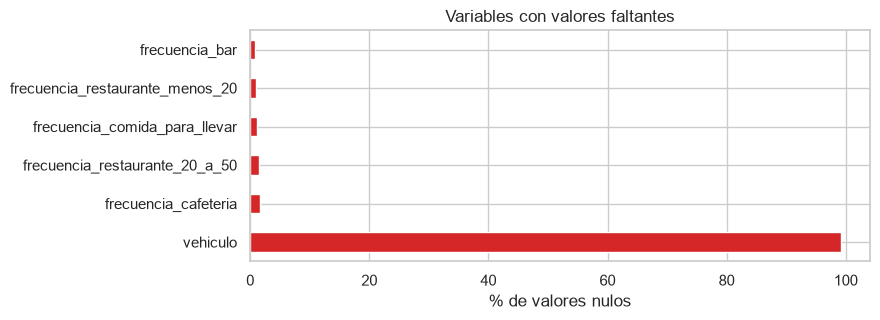

,n_nulos,pct
vehiculo,12556,99.15
frecuencia_cafeteria,217,1.71
frecuencia_restaurante_20_a_50,189,1.49
frecuencia_comida_para_llevar,151,1.19
frecuencia_restaurante_menos_20,130,1.03
frecuencia_bar,107,0.84


In [6]:
nulos = datos.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
ax = (nulos / len(datos) * 100).plot(kind="barh", figsize=(8, 3), color="tab:red")
ax.set_xlabel("% de valores nulos")
ax.set_title("Variables con valores faltantes")
plt.show()
nulos.to_frame("n_nulos").assign(pct=lambda x: (x.n_nulos / len(datos) * 100).round(2))

### 1.4 Registros duplicados
Se revisan duplicados exactos y también registros con las mismas características pero **etiqueta distinta** (conflictivos).

In [7]:
X_cols = [c for c in datos.columns if c != "acepta_cupon"]
print("Duplicados exactos (incluyendo la etiqueta):", datos.duplicated().sum())
print("Duplicados en las características:          ", datos.duplicated(subset=X_cols).sum())

conflictos = datos.groupby(X_cols, dropna=False)["acepta_cupon"].nunique()
print("Grupos de características con etiquetas en conflicto:", (conflictos > 1).sum())

Duplicados exactos (incluyendo la etiqueta): 74
Duplicados en las características:           97
Grupos de características con etiquetas en conflicto: 23


### 1.5 Variables constantes y redundantes
Se revisan relaciones que el diccionario sugiere entre variables: `clima` y `temperatura`, las variables de distancia (`tiempo_cupon_mayor_*`) y las de dirección.

In [8]:
print("Variables con un único valor:", [c for c in datos.columns if datos[c].nunique(dropna=False) == 1])

Variables con un único valor: ['tiempo_cupon_mayor_5min']


In [9]:
pd.crosstab(datos["clima"], datos["temperatura"])

temperatura,30,55,80
clima,,,
Lluvioso,0,1208,0
Nevado,1404,0,0
Soleado,911,2628,6513


In [10]:
print("¿direccion_opuesta es siempre lo contrario de misma_direccion?",
      ((datos["misma_direccion"] == "Sí") == (datos["direccion_opuesta"] == "No")).all())
pd.crosstab(datos["tiempo_cupon_mayor_15min"], datos["tiempo_cupon_mayor_25min"])

¿direccion_opuesta es siempre lo contrario de misma_direccion? True


tiempo_cupon_mayor_25min,No,Sí
tiempo_cupon_mayor_15min,,
No,5551,0
Sí,5602,1511


### 1.5.1 Consistencia lógica entre variables
Se buscan combinaciones de valores que, aunque individualmente válidas, son contradictorias o poco plausibles entre sí.

In [11]:
# Viaja con hijos pero reporta no tener hijos
inc_hijos = (datos["acompanante"] == "Hijo(s)") & (datos["tiene_hijos"] == "No")
print("acompanante = Hijo(s) y tiene_hijos = No:", inc_hijos.sum())
print(datos[inc_hijos]["cupon"].value_counts().to_dict(), "\n")

# Jubilados jóvenes
jubilados = datos[datos["ocupacion"] == "Jubilado(a)"]
pd.crosstab(jubilados["edad"], jubilados["cupon"], margins=True)

acompanante = Hijo(s) y tiene_hijos = No: 17
{'Restaurante(20-50)': 5, 'Cafetería': 4, 'Restaurante(<20)': 3, 'Bar': 3, 'Comida para llevar': 2} 



cupon,Bar,Cafetería,Comida para llevar,Restaurante(20-50),Restaurante(<20),All
edad,,,,,,
26,3,10,3,2,4,22
36,2,10,4,0,6,22
46,4,13,6,3,8,34
50 o más,66,130,77,50,93,416
All,75,163,90,55,111,494


In [12]:
# Los mismos casos en los datos de prueba
print("Prueba - Hijo(s) sin hijos:", ((prueba["acompanante"] == "Hijo(s)") & (prueba["tiene_hijos"] == "No")).sum())
print("Prueba - edades de jubilados:", prueba.loc[prueba["ocupacion"] == "Jubilado(a)", "edad"].tolist())

Prueba - Hijo(s) sin hijos: 0
Prueba - edades de jubilados: ['50 o más']


### 1.6 Subconjuntos por tipo de cupón y distribución de `acepta_cupon`
El estudio se centra en los cupones de **Cafetería** y **Restaurante(<20)**, por lo que se construye un subconjunto para cada uno y se analiza la distribución de la variable objetivo.

In [13]:
pd.crosstab(datos["cupon"], datos["acepta_cupon"], margins=True)

acepta_cupon,No,Sí,All
cupon,,,
Bar,1190,827,2017
Cafetería,1997,1989,3986
Comida para llevar,633,1760,2393
Restaurante(20-50),834,658,1492
Restaurante(<20),814,1962,2776
All,5468,7196,12664


Cafetería: 3986 registros
                 n   pct
acepta_cupon            
No            1997  50.1
Sí            1989  49.9 

Restaurante(<20): 2776 registros
                 n   pct
acepta_cupon            
Sí            1962  70.7
No             814  29.3 



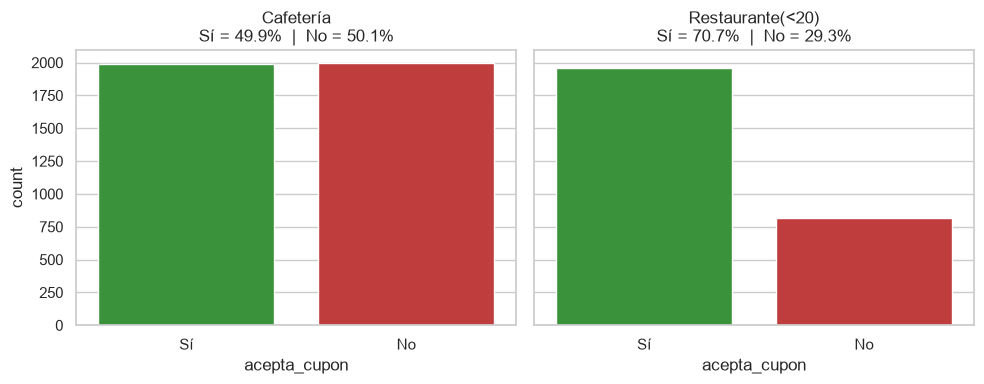

In [14]:
subconjuntos = {c: datos[datos["cupon"] == c].copy() for c in CUPONES}

for c, df in subconjuntos.items():
    print(f"{c}: {df.shape[0]} registros")
    print(df["acepta_cupon"].value_counts().to_frame("n").assign(pct=lambda x: (x.n / x.n.sum() * 100).round(1)), "\n")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (c, df) in zip(axes, subconjuntos.items()):
    sns.countplot(data=df, x="acepta_cupon", order=["Sí", "No"], ax=ax, hue="acepta_cupon", palette={"Sí": "tab:green", "No": "tab:red"}, legend=False)
    pct = df["acepta_cupon"].value_counts(normalize=True) * 100
    ax.set_title(f"{c}\nSí = {pct['Sí']:.1f}%  |  No = {pct['No']:.1f}%")
    ax.set_xlabel("acepta_cupon")
plt.tight_layout()
plt.show()

In [15]:
# Calidad de datos dentro de cada subconjunto
calidad = pd.DataFrame({
    c: {
        "registros": len(df),
        "duplicados_exactos": df.duplicated().sum(),
        "duplicados_en_X": df.duplicated(subset=X_cols).sum(),
        **{f"nulos_{col}": df[col].isna().sum() for col in nulos.index},
    }
    for c, df in subconjuntos.items()
})
calidad

,Cafetería,Restaurante(<20)
registros,3986,2776
duplicados_exactos,7,7
duplicados_en_X,11,10
nulos_vehiculo,3949,2751
nulos_frecuencia_cafeteria,72,47
nulos_frecuencia_restaurante_20_a_50,55,43
nulos_frecuencia_comida_para_llevar,57,34
nulos_frecuencia_restaurante_menos_20,50,27
nulos_frecuencia_bar,37,23


### 1.7 Relación de las variables con la aceptación en cada subconjunto
Se calcula la tasa de aceptación (% de "Sí") por categoría de algunas variables de contexto y de perfil, para tener una primera intuición de qué factores influyen en cada cupón.

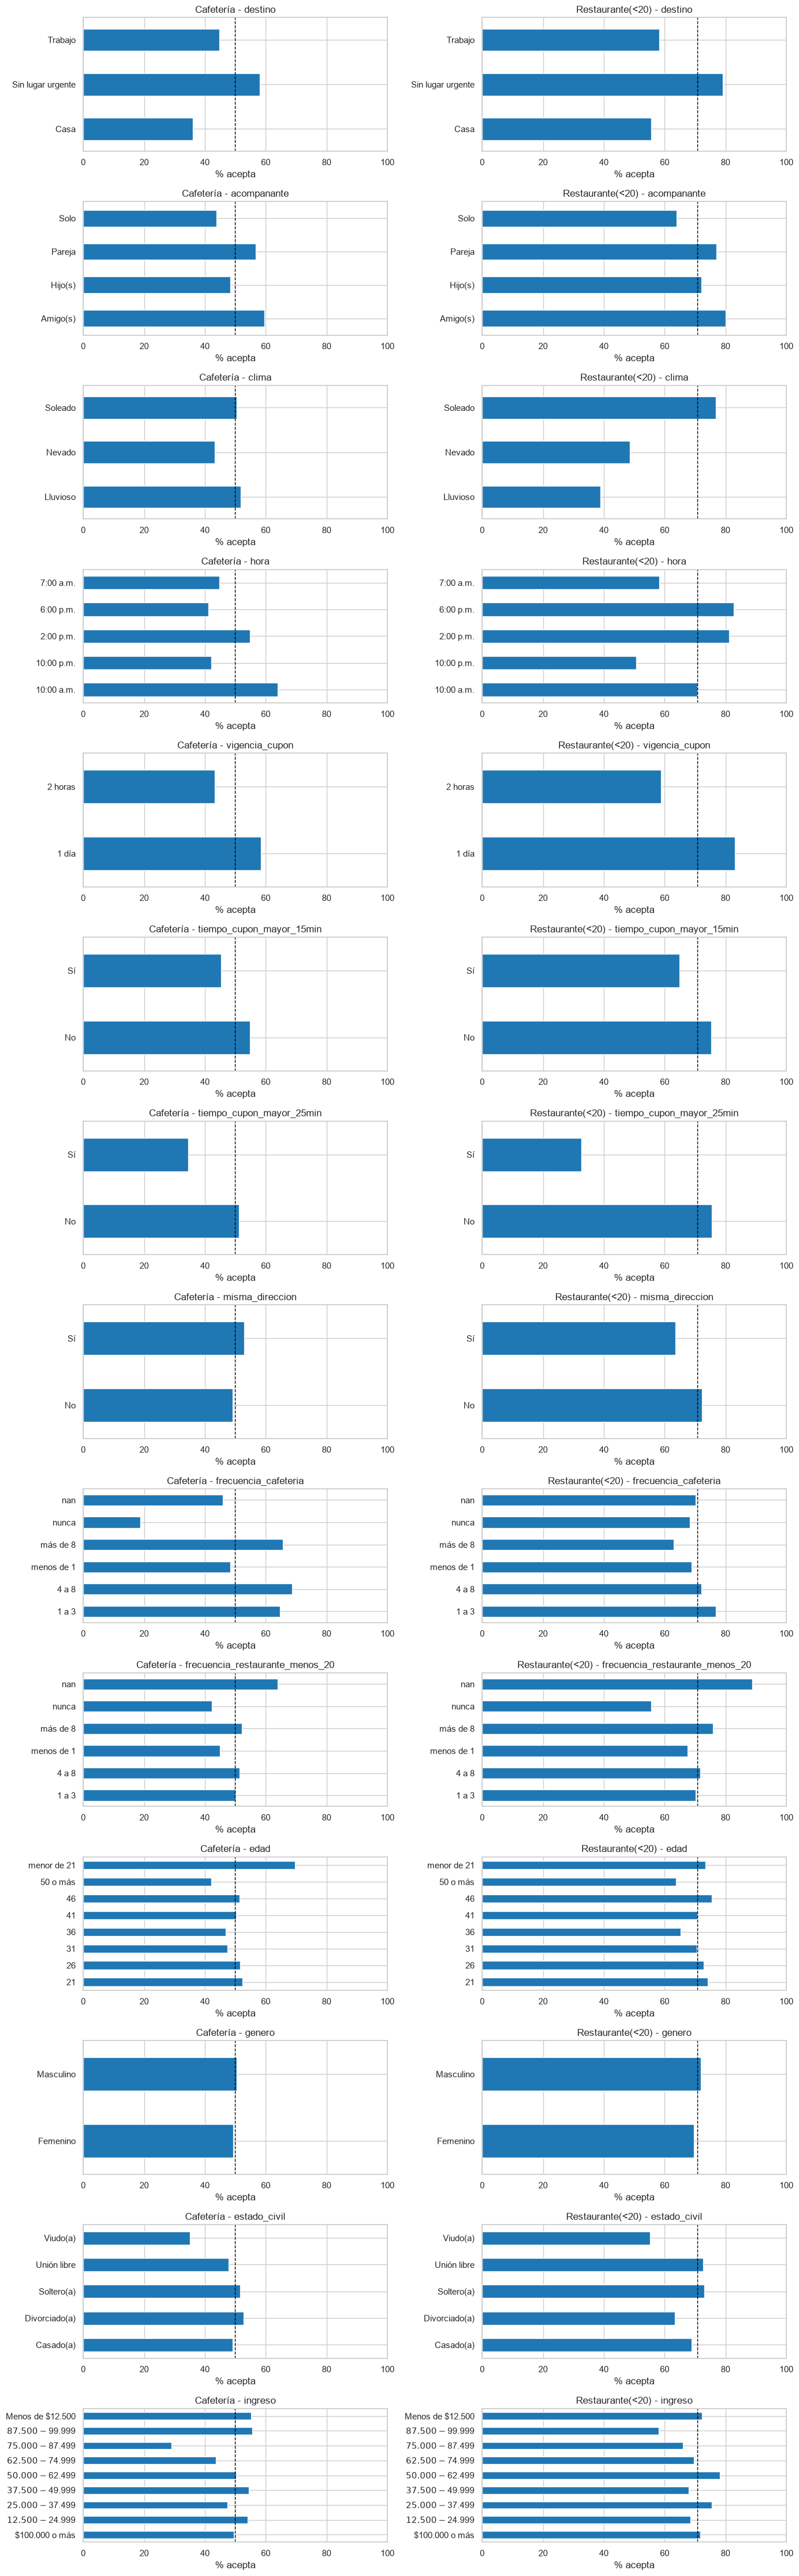

In [16]:
def tasa_aceptacion(df, col):
    return (df.groupby(col, dropna=False)["acepta_cupon"]
              .apply(lambda s: (s == "Sí").mean() * 100)
              .rename("tasa_aceptacion_%"))

vars_exploracion = ["destino", "acompanante", "clima", "hora", "vigencia_cupon",
                    "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min", "misma_direccion",
                    "frecuencia_cafeteria", "frecuencia_restaurante_menos_20",
                    "edad", "genero", "estado_civil", "ingreso"]

fig, axes = plt.subplots(len(vars_exploracion), 2, figsize=(14, 3.2 * len(vars_exploracion)))
for i, col in enumerate(vars_exploracion):
    for j, (c, df) in enumerate(subconjuntos.items()):
        ax = axes[i, j]
        tasa_aceptacion(df, col).plot(kind="barh", ax=ax, color="tab:blue")
        ax.axvline((df["acepta_cupon"] == "Sí").mean() * 100, color="black", ls="--", lw=1)
        ax.set_xlim(0, 100)
        ax.set_title(f"{c} - {col}")
        ax.set_xlabel("% acepta")
        ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 1.8 Datos de prueba
Se verifica que los datos sin etiquetar tengan la misma estructura que los de entrenamiento.

In [17]:
print("Columnas que difieren:", set(datos.columns) ^ set(prueba.columns))
print(prueba["cupon"].value_counts(), "\n")
print("Nulos en prueba:\n", prueba.isna().sum()[prueba.isna().sum() > 0])

Columnas que difieren: {'acepta_cupon'}
cupon
Cafetería           10
Restaurante(<20)    10
Name: count, dtype: int64 

Nulos en prueba:
 vehiculo    20
dtype: int64


### 1.9 Conclusiones de la exploración

**Calidad de los datos**
- **`vehiculo`** tiene más del 99% de valores nulos (solo ~108 registros con valor, y en prueba está vacía en todas las filas). No aporta información útil.
- **`tiempo_cupon_mayor_5min`** es **constante** (siempre "Sí"), por lo que no tiene poder predictivo.
- **`direccion_opuesta`** es **exactamente el complemento** de `misma_direccion`: es redundante.
- **`temperatura`** está casi determinada por `clima` (Lluvioso → 55, Nevado → 30, Soleado → 30/55/80). Aporta poca información adicional, aunque distingue días soleados fríos de cálidos.
- Las variables `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` están anidadas (si es mayor a 25 min, también es mayor a 15 min): juntas codifican una distancia ordinal de 3 niveles.
- Las cinco variables de **frecuencia** tienen entre 0.8% y 1.7% de valores nulos.
- Hay **74 duplicados exactos** en el total de datos (7 en cada subconjunto de interés) y unos pocos registros con las mismas características pero **etiqueta en conflicto**.
- **Inconsistencia lógica:** 17 registros viajan con `acompanante = Hijo(s)` pero reportan `tiene_hijos = No` (4 en Cafetería y 3 en Restaurante(<20)). No es posible saber cuál de los dos campos es el erróneo (incluso "Hijo(s)" podría referirse a hijastros o sobrinos).
- **Valores sospechosos:** hay jubilados de 26 y 36 años (44 registros en total; 20 en Cafetería y 10 en Restaurante(<20)). Son poco frecuentes, pero plausibles (p. ej. jubilación por invalidez), por lo que se consideran posibles atípicos y no errores.
- No se encontraron categorías mal escritas ni espacios sobrantes; los valores corresponden a los del diccionario.

**Distribución de `acepta_cupon`**
- **Cafetería** (3986 registros): prácticamente **balanceada** (~50% Sí / ~50% No).
- **Restaurante(<20)** (2776 registros): **desbalanceada** (~71% Sí / ~29% No). La **clase minoritaria es "No"** (rechazo), lo que hay que tener en cuenta al evaluar el recall de la clase minoritaria en la Actividad 6.

**Primeras intuiciones** (diferencia entre la categoría con mayor y menor tasa de aceptación, considerando categorías con al menos 50 registros)
- **Cafetería:** la variable más relacionada es `frecuencia_cafeteria` (~50 puntos porcentuales de diferencia entre quienes nunca van y quienes van seguido), seguida de `ocupacion`, `edad`, `ingreso`, `hora` y `destino`.
- **Restaurante(<20):** dominan las variables de **contexto**: la distancia (`tiempo_cupon_mayor_25min`, ~43 p.p.), el `clima`, la `hora`, la `vigencia_cupon` y el `destino`; la frecuencia de visita a este tipo de restaurante pesa menos que en Cafetería.
- `genero` y `tiene_hijos` casi no cambian la tasa de aceptación en ninguno de los dos cupones (< 3 p.p.). En cambio, variables demográficas como `edad`, `ingreso` y `ocupacion` sí muestran diferencias importantes, sobre todo en Cafetería; esto es relevante para el análisis de sesgos (pueden actuar como predictores directos o como *proxies* de otros factores).
- Estas son relaciones univariadas (una variable a la vez); los modelos permitirán ver su efecto en conjunto.


## 2. Limpieza y preparación de los datos

Con base en los hallazgos de la exploración se toman las siguientes decisiones:

| Problema detectado | Decisión | Justificación |
|:---|:---|:---|
| `vehiculo` con >99% de nulos (100% en prueba) | Eliminar la columna | No hay información suficiente para imputarla ni para aprender de ella. |
| `tiempo_cupon_mayor_5min` constante | Eliminar la columna | Una variable con un solo valor no puede discriminar entre clases. |
| `direccion_opuesta` = complemento de `misma_direccion` | Eliminar `direccion_opuesta` | Es información duplicada; mantener ambas solo agrega colinealidad perfecta (problemática en regresión logística). |
| `cupon` constante dentro de cada subconjunto | Excluirla de las características | Al entrenar un modelo por tipo de cupón, deja de aportar información. |
| Duplicados exactos (7 en cada subconjunto) | Eliminarlos | Evitan que un mismo registro aparezca en entrenamiento y test a la vez (sobreestimando el desempeño). Al ser tan pocos, no alteran la distribución. |
| Registros con características iguales y etiqueta en conflicto | Mantenerlos | Reflejan el ruido real del problema (dos conductores con el mismo perfil pueden decidir distinto); no hay criterio para elegir cuál etiqueta es "correcta". |
| `acompanante = Hijo(s)` con `tiene_hijos = No` | Mantener y documentar | No es posible saber cuál campo es erróneo; corregirlo sería adivinar y eliminarlos (3-4 por subconjunto) no cambia los resultados. |
| Jubilados de 26 y 36 años | Mantener y documentar | Son plausibles (jubilación anticipada o por invalidez); no hay evidencia de que sean errores. |
| Nulos en las variables de frecuencia (<2%) | Imputar con la **moda**, dentro del pipeline | Son variables categóricas con pocos nulos; la moda es una imputación razonable. Hacerlo dentro del pipeline evita fuga de información (la moda se calcula solo con el entrenamiento de cada *fold*) y permite que el modelo maneje nulos en producción. |
| `temperatura` casi determinada por `clima` | Mantenerla como numérica | Distingue días soleados fríos (30°F) de cálidos (80°F), información que `clima` no tiene. |
| Variables ordinales en texto (`hora`, `edad`, `educacion`, `ingreso`, frecuencias) | **Codificación ordinal** con el orden del diccionario | Conserva el orden natural de las categorías con una sola columna por variable. |
| Variables nominales | **One-hot encoding** | No tienen orden; una codificación numérica impondría un orden artificial. |
| Escalas distintas (solo para regresión logística) | `StandardScaler` sobre ordinales y numéricas | La regularización L1/L2 penaliza los coeficientes, por lo que las variables deben estar en escalas comparables. Los árboles y Random Forest no lo necesitan. |

### 2.1 Limpieza de columnas y duplicados

In [18]:
COLS_ELIMINAR = ["vehiculo", "tiempo_cupon_mayor_5min", "direccion_opuesta"]

def limpiar(df, eliminar_duplicados=True):
    df = df.drop(columns=COLS_ELIMINAR)
    if eliminar_duplicados:
        df = df.drop_duplicates()
    return df.reset_index(drop=True)

datos_limpios = {c: limpiar(df) for c, df in subconjuntos.items()}
# Los datos de prueba no se deduplican: se debe predecir cada una de sus filas
prueba_limpia = limpiar(prueba, eliminar_duplicados=False)

for c in CUPONES:
    print(f"{c}: {subconjuntos[c].shape} -> {datos_limpios[c].shape}")
print(f"Prueba: {prueba.shape} -> {prueba_limpia.shape}")

Cafetería: (3986, 26) -> (3979, 23)
Restaurante(<20): (2776, 26) -> (2769, 23)
Prueba: (20, 25) -> (20, 22)


### 2.2 Definición de los tipos de variables y del orden de las ordinales
El orden de las categorías ordinales se toma del diccionario de datos. Se verifica que todos los valores presentes en los datos estén contemplados.

In [19]:
ORDEN_FRECUENCIA = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]

ORDINALES = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
                  "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999",
                "$50.000 - $62.499", "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999",
                "$100.000 o más"],
    "frecuencia_bar": ORDEN_FRECUENCIA,
    "frecuencia_cafeteria": ORDEN_FRECUENCIA,
    "frecuencia_comida_para_llevar": ORDEN_FRECUENCIA,
    "frecuencia_restaurante_menos_20": ORDEN_FRECUENCIA,
    "frecuencia_restaurante_20_a_50": ORDEN_FRECUENCIA,
}
NUMERICAS = ["temperatura"]
NOMINALES = ["destino", "acompanante", "clima", "vigencia_cupon", "genero", "estado_civil", "tiene_hijos",
             "ocupacion", "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min", "misma_direccion"]
OBJETIVO = "acepta_cupon"

# Verificación: todas las columnas están clasificadas y todos los valores ordinales están en el orden definido
columnas_x = set(datos_limpios[CUPONES[0]].columns) - {OBJETIVO, "cupon"}
assert columnas_x == set(ORDINALES) | set(NUMERICAS) | set(NOMINALES), columnas_x ^ (set(ORDINALES) | set(NUMERICAS) | set(NOMINALES))
for col, orden in ORDINALES.items():
    for df in [*datos_limpios.values(), prueba_limpia]:
        faltantes = set(df[col].dropna()) - set(orden)
        assert not faltantes, f"{col}: {faltantes}"
print(f"OK: {len(ORDINALES)} ordinales, {len(NUMERICAS)} numérica, {len(NOMINALES)} nominales")

OK: 9 ordinales, 1 numérica, 11 nominales


### 2.3 Partición en entrenamiento y test
Para cada tipo de cupón se separa un 20% de los datos como conjunto de **test**, que solo se usará para la evaluación final de los modelos (Actividad 7). La partición es **estratificada** por `acepta_cupon` para conservar la proporción de clases, algo especialmente importante en Restaurante(<20), que está desbalanceado.

La variable objetivo se codifica como **1 = Sí (acepta)** y **0 = No (rechaza)**, de modo que las métricas de precisión, recall y F1 se calculan por defecto sobre la aceptación del cupón.

In [20]:
from sklearn.model_selection import train_test_split

def separar_X_y(df):
    X = df.drop(columns=[OBJETIVO, "cupon"])
    y = (df[OBJETIVO] == "Sí").astype(int)
    return X, y

particiones = {}
for c in CUPONES:
    X, y = separar_X_y(datos_limpios[c])
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    particiones[c] = {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test}

pd.DataFrame({
    c: {
        "n_train": len(p["y_train"]), "n_test": len(p["y_test"]),
        "% Sí train": round(p["y_train"].mean() * 100, 1), "% Sí test": round(p["y_test"].mean() * 100, 1),
    }
    for c, p in particiones.items()
})

,Cafetería,Restaurante(<20)
n_train,3183.0,2215.0
n_test,796.0,554.0
% Sí train,49.8,70.7
% Sí test,49.9,70.8


### 2.4 Preprocesamiento como parte del pipeline
El preprocesamiento se define con un `ColumnTransformer` que luego se integrará como primer paso del `Pipeline` de cada modelo. Así, la imputación y la codificación se ajustan **solo con los datos de entrenamiento** de cada *fold* durante la validación cruzada, evitando fuga de información.

- **Ordinales:** imputación con la moda → `OrdinalEncoder` con el orden del diccionario (→ `StandardScaler` en regresión logística).
- **Numéricas:** imputación con la moda (→ `StandardScaler` en regresión logística).
- **Nominales:** imputación con la moda → `OneHotEncoder` (`handle_unknown="ignore"` para no fallar si aparece una categoría nueva en producción).

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler

def crear_preprocesador(escalar=False):
    pasos_ordinales = [
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OrdinalEncoder(categories=list(ORDINALES.values()),
                                     handle_unknown="use_encoded_value", unknown_value=-1)),
    ]
    pasos_numericos = [("imputar", SimpleImputer(strategy="most_frequent"))]
    if escalar:
        pasos_ordinales.append(("escalar", StandardScaler()))
        pasos_numericos.append(("escalar", StandardScaler()))

    return ColumnTransformer([
        ("ordinales", Pipeline(pasos_ordinales), list(ORDINALES)),
        ("numericas", Pipeline(pasos_numericos), NUMERICAS),
        ("nominales", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), NOMINALES),
    ])

# Ejemplo: resultado del preprocesamiento sobre el entrenamiento de Cafetería
pre = crear_preprocesador(escalar=False)
X_ejemplo = pre.fit_transform(particiones["Cafetería"]["X_train"])
print("Dimensión antes:", particiones["Cafetería"]["X_train"].shape, "-> después:", X_ejemplo.shape)
print("Nulos después del preprocesamiento:", np.isnan(X_ejemplo).sum())
pd.DataFrame(X_ejemplo, columns=pre.get_feature_names_out()).head()

Dimensión antes: (3183, 21) -> después: (3183, 62)
Nulos después del preprocesamiento: 0


,ordinales__hora,ordinales__edad,ordinales__educacion,ordinales__ingreso,ordinales__frecuencia_bar,ordinales__frecuencia_cafeteria,ordinales__frecuencia_comida_para_llevar,ordinales__frecuencia_restaurante_menos_20,ordinales__frecuencia_restaurante_20_a_50,numericas__temperatura,nominales__destino_Casa,nominales__destino_Sin lugar urgente,nominales__destino_Trabajo,nominales__acompanante_Amigo(s),nominales__acompanante_Hijo(s),nominales__acompanante_Pareja,nominales__acompanante_Solo,nominales__clima_Lluvioso,nominales__clima_Nevado,nominales__clima_Soleado,nominales__vigencia_cupon_1 día,nominales__vigencia_cupon_2 horas,nominales__genero_Femenino,nominales__genero_Masculino,nominales__estado_civil_Casado(a),...,nominales__ocupacion_Computación y Matemáticas,nominales__ocupacion_Construcción y Extracción,nominales__ocupacion_Cuidado Personal y Servicios,nominales__ocupacion_Desempleado(a),"nominales__ocupacion_Educación, Formación y Bibliotecología",nominales__ocupacion_Estudiante,nominales__ocupacion_Gerencia,"nominales__ocupacion_Instalación, Mantenimiento y Reparación",nominales__ocupacion_Jubilado(a),nominales__ocupacion_Limpieza y Mantenimiento de Edificios,nominales__ocupacion_Negocios y Finanzas,nominales__ocupacion_Preparación y Servicio de Alimentos,nominales__ocupacion_Producción,nominales__ocupacion_Profesionales y Técnicos de la Salud,nominales__ocupacion_Servicios Comunitarios y Sociales,nominales__ocupacion_Servicios de Protección y Seguridad,nominales__ocupacion_Transporte y Manejo de Materiales,nominales__ocupacion_Ventas y afines,nominales__ocupacion_Área Legal,nominales__tiempo_cupon_mayor_15min_No,nominales__tiempo_cupon_mayor_15min_Sí,nominales__tiempo_cupon_mayor_25min_No,nominales__tiempo_cupon_mayor_25min_Sí,nominales__misma_direccion_No,nominales__misma_direccion_Sí
0,1.0,2.0,5.0,5.0,3.0,2.0,3.0,3.0,2.0,80.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,2.0,4.0,5.0,8.0,2.0,1.0,2.0,3.0,2.0,80.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,2.0,5.0,4.0,8.0,1.0,2.0,2.0,3.0,1.0,80.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
3,1.0,2.0,2.0,6.0,0.0,0.0,2.0,3.0,1.0,80.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
4,2.0,1.0,4.0,5.0,0.0,1.0,2.0,1.0,1.0,80.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0


**Resumen del Paso 2:** cada subconjunto queda sin columnas inútiles ni duplicados, separado en entrenamiento (80%) y test (20%) de forma estratificada, y con un preprocesador reutilizable que se incorporará a los pipelines de los tres algoritmos en las actividades 3 a 5.

## 3. Regresión logística

### 3.1 Funciones de apoyo para la búsqueda de hiperparámetros y la evaluación
Para los tres algoritmos se sigue el mismo procedimiento, que se encapsula en dos funciones:

- `buscar_hiperparametros`: ejecuta un `GridSearchCV` con **validación cruzada estratificada de 5 folds** sobre el conjunto de entrenamiento. La métrica de selección es el **F1-score** de la clase "Sí", porque combina precisión y recall en una sola medida y es la métrica con la que se evaluarán las predicciones finales. Para Restaurante(<20), además, el F1 es más informativo que la exactitud (*accuracy*), que se infla con el desbalance.
- `evaluar_en_test`: evalúa el mejor modelo encontrado sobre el conjunto de test (que no participó en la búsqueda) y guarda precisión, recall y F1 de la clase "Sí", junto con el recall de la clase "No" (minoritaria en Restaurante(<20)).

La selección de hiperparámetros se hace **solo con la validación cruzada**; el test se reserva para la comparación final entre algoritmos (Actividad 7).

In [22]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
modelos = {}     # (algoritmo, cupón) -> GridSearchCV ajustado
resultados = []  # métricas de test de cada modelo

def buscar_hiperparametros(pipeline, grid, cupon, nombre, scoring="f1"):
    p = particiones[cupon]
    busqueda = GridSearchCV(pipeline, grid, scoring=scoring, cv=CV, n_jobs=-1, return_train_score=True)
    busqueda.fit(p["X_train"], p["y_train"])
    modelos[(nombre, cupon)] = busqueda
    print(f"{nombre} - {cupon}")
    print(f"  Mejores hiperparámetros: {busqueda.best_params_}")
    print(f"  {scoring} en validación cruzada: {busqueda.best_score_:.4f}")
    return busqueda

def top_configuraciones(busqueda, n=5):
    cv = pd.DataFrame(busqueda.cv_results_)
    cols = [c for c in cv.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
    return cv[cols].sort_values("rank_test_score").head(n)

def evaluar_en_test(modelo, cupon, nombre):
    p = particiones[cupon]
    y_pred = modelo.predict(p["X_test"])
    fila = {
        "algoritmo": nombre, "cupon": cupon,
        "precision": precision_score(p["y_test"], y_pred),
        "recall": recall_score(p["y_test"], y_pred),
        "f1": f1_score(p["y_test"], y_pred),
        "recall_No": recall_score(p["y_test"], y_pred, pos_label=0),
        "accuracy": accuracy_score(p["y_test"], y_pred),
    }
    resultados[:] = [r for r in resultados if (r["algoritmo"], r["cupon"]) != (nombre, cupon)]
    resultados.append(fila)
    return fila

def mostrar_evaluacion(nombre):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, cupon in zip(axes, CUPONES):
        p = particiones[cupon]
        modelo = modelos[(nombre, cupon)]
        evaluar_en_test(modelo, cupon, nombre)
        y_pred = modelo.predict(p["X_test"])
        print(f"===== {nombre} - {cupon} (test) =====")
        print(classification_report(p["y_test"], y_pred, target_names=["No", "Sí"], digits=3))
        ConfusionMatrixDisplay.from_predictions(p["y_test"], y_pred, display_labels=["No", "Sí"],
                                                cmap="Blues", ax=ax, colorbar=False)
        ax.set_title(f"{nombre} - {cupon}")
    plt.tight_layout()
    plt.show()
    return pd.DataFrame([r for r in resultados if r["algoritmo"] == nombre]).set_index("cupon").round(4)

### 3.2 Pipeline y espacio de búsqueda
El pipeline está compuesto por el preprocesador **con escalado** (necesario para que la regularización penalice por igual a todas las variables) y el clasificador `LogisticRegression`.

Se exploran:
- **Tipo de regularización**, controlado por `l1_ratio`: `0` = **L2 (Ridge)**, `1` = **L1 (Lasso)** y `0.5` = **ElasticNet** (mezcla de ambas). *Nota:* a partir de scikit-learn 1.8 el parámetro `penalty` está deprecado y el tipo de regularización se define exclusivamente con `l1_ratio`.
- **Solver**: no todos los solvers soportan todas las penalizaciones, por lo que la grilla se define como una lista de combinaciones válidas:
  - L2: `lbfgs`, `liblinear`, `newton-cg`, `saga`
  - L1: `liblinear`, `saga`
  - ElasticNet: `saga`
- **Fuerza de regularización `C`** (inverso de la regularización: valores pequeños = modelo más simple): 0.001 a 100.

In [23]:
from sklearn.linear_model import LogisticRegression

def crear_pipeline_lr():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador(escalar=True)),
        ("modelo", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ])

VALORES_C = [0.001, 0.01, 0.1, 1, 10, 100]
GRID_LR = [
    {"modelo__l1_ratio": [0], "modelo__solver": ["lbfgs", "liblinear", "newton-cg", "saga"], "modelo__C": VALORES_C},  # L2
    {"modelo__l1_ratio": [1], "modelo__solver": ["liblinear", "saga"], "modelo__C": VALORES_C},                       # L1
    {"modelo__l1_ratio": [0.5], "modelo__solver": ["saga"], "modelo__C": VALORES_C},                                  # ElasticNet
]
print("Combinaciones a evaluar por cupón:", sum(len(g["modelo__solver"]) * len(g["modelo__C"]) for g in GRID_LR), "x 5 folds")

Combinaciones a evaluar por cupón: 42 x 5 folds


### 3.3 Búsqueda de hiperparámetros: Cafetería

In [24]:
lr_cafe = buscar_hiperparametros(crear_pipeline_lr(), GRID_LR, "Cafetería", "Regresión logística")
top_configuraciones(lr_cafe)

Regresión logística - Cafetería
  Mejores hiperparámetros: {'modelo__C': 1, 'modelo__l1_ratio': 0.5, 'modelo__solver': 'saga'}
  f1 en validación cruzada: 0.7073


,param_modelo__C,param_modelo__l1_ratio,param_modelo__solver,mean_test_score,std_test_score,rank_test_score
39,1.0,0.5,saga,0.707348,0.019351,1
10,0.1,0.0,newton-cg,0.707042,0.021878,2
9,0.1,0.0,liblinear,0.706825,0.022631,3
11,0.1,0.0,saga,0.706639,0.021792,4
8,0.1,0.0,lbfgs,0.706417,0.021758,5


### 3.4 Búsqueda de hiperparámetros: Restaurante(<20)

In [25]:
lr_rest = buscar_hiperparametros(crear_pipeline_lr(), GRID_LR, "Restaurante(<20)", "Regresión logística")
top_configuraciones(lr_rest)

Regresión logística - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__l1_ratio': 0, 'modelo__solver': 'lbfgs'}
  f1 en validación cruzada: 0.8460


,param_modelo__C,param_modelo__l1_ratio,param_modelo__solver,mean_test_score,std_test_score,rank_test_score
8,0.10,0.0,lbfgs,0.846042,0.007627,1
11,0.10,0.0,saga,0.846042,0.007627,1
10,0.10,0.0,newton-cg,0.846042,0.007627,1
9,0.10,0.0,liblinear,0.846042,0.007627,1
26,0.01,1.0,liblinear,0.845589,0.005697,5


### 3.5 Efecto de la regularización
Se compara el mejor F1 de validación cruzada obtenido con cada tipo de regularización y cada valor de `C` (tomando el mejor solver en cada caso).

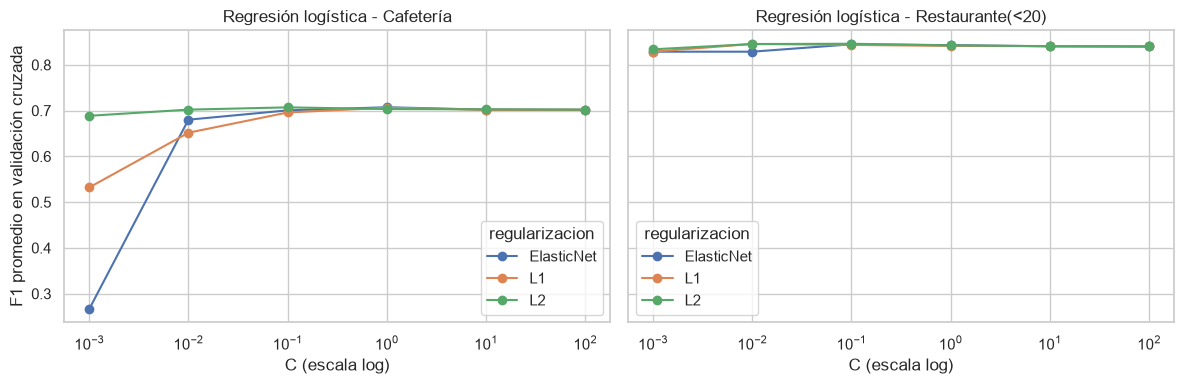

In [26]:
NOMBRE_REG = {0: "L2", 1: "L1", 0.5: "ElasticNet"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, cupon in zip(axes, CUPONES):
    cv = pd.DataFrame(modelos[("Regresión logística", cupon)].cv_results_)
    cv["regularizacion"] = cv["param_modelo__l1_ratio"].map(NOMBRE_REG)
    curvas = cv.groupby(["regularizacion", "param_modelo__C"])["mean_test_score"].max().unstack(0)
    curvas.plot(ax=ax, marker="o", logx=True)
    ax.set_title(f"Regresión logística - {cupon}")
    ax.set_xlabel("C (escala log)")
    ax.set_ylabel("F1 promedio en validación cruzada")
plt.tight_layout()
plt.show()

### 3.6 Evaluación sobre test

===== Regresión logística - Cafetería (test) =====
              precision    recall  f1-score   support

          No      0.701     0.682     0.691       399
          Sí      0.689     0.708     0.698       397

    accuracy                          0.695       796
   macro avg      0.695     0.695     0.695       796
weighted avg      0.695     0.695     0.695       796

===== Regresión logística - Restaurante(<20) (test) =====
              precision    recall  f1-score   support

          No      0.611     0.340     0.437       162
          Sí      0.769     0.911     0.834       392

    accuracy                          0.744       554
   macro avg      0.690     0.625     0.635       554
weighted avg      0.723     0.744     0.718       554



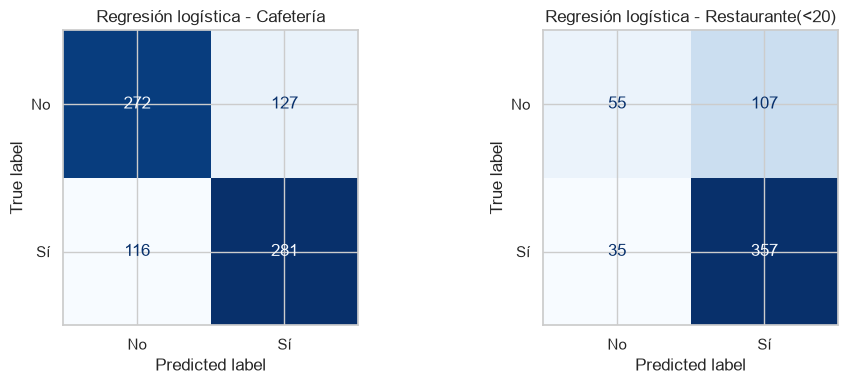

,algoritmo,precision,recall,f1,recall_No,accuracy
cupon,,,,,,
Cafetería,Regresión logística,0.6887,0.7078,0.6981,0.6817,0.6947
Restaurante(<20),Regresión logística,0.7694,0.9107,0.8341,0.3395,0.7437


In [27]:
mostrar_evaluacion("Regresión logística")

### 3.7 Conclusiones de la regresión logística

| Cupón | Mejor configuración | F1 CV | F1 test | Recall "No" test |
|:---|:---|:---:|:---:|:---:|
| Cafetería | ElasticNet (`l1_ratio=0.5`), `saga`, `C=1` | 0.707 | 0.698 | 0.682 |
| Restaurante(<20) | L2, `lbfgs`, `C=0.1` | 0.846 | 0.834 | 0.340 |

- **Tipo de regularización y solver:** en ambos cupones las mejores configuraciones están prácticamente empatadas (diferencias < 0.001 en F1). Con L2, los cuatro solvers llegan a la misma solución, lo que es esperable porque optimizan la misma función convexa; el solver afecta la velocidad de convergencia, no el resultado. El hiperparámetro que realmente importa es **`C`**: con valores muy pequeños (regularización fuerte) el desempeño cae, como se ve en la gráfica 3.5.
- **El F1 en test es muy similar al de validación cruzada**, lo que indica que el modelo no está sobreajustado y que la estimación de la validación cruzada es confiable.
- **Cafetería:** el modelo es equilibrado entre clases (precisión y recall ≈ 0.69-0.71 para ambas).
- **Restaurante(<20):** el F1 de la clase "Sí" es alto (0.834), pero en buena parte porque el modelo tiende a predecir "Sí": el **recall de la clase "No" es solo 0.34**, es decir, identifica apenas 1 de cada 3 rechazos. Esto es un efecto del desbalance de clases que se evaluará en la Actividad 6.


## 4. Árboles de decisión

### 4.1 Pipeline y espacio de búsqueda
El pipeline usa el preprocesador **sin escalado**: los árboles dividen por umbrales sobre cada variable, por lo que la escala no afecta las particiones. La codificación ordinal es especialmente adecuada aquí, porque un umbral como `edad <= 2.5` agrupa rangos de edad contiguos.

Se exploran:
- **`max_depth`** (profundidad máxima): controla la complejidad del árbol. Valores bajos → modelos simples que pueden subajustar; `None` → el árbol crece hasta que las hojas son puras (riesgo de sobreajuste).
- **`min_samples_leaf`** (mínimo de muestras por hoja): evita hojas con muy pocos registros, que suelen capturar ruido.
- **`criterion`** (criterio de división): `gini` (impureza de Gini), `entropy` y `log_loss` (ganancia de información). En scikit-learn, `entropy` y `log_loss` son equivalentes para clasificación; se incluyen ambos para verificarlo.

In [28]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

def crear_pipeline_arbol():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador(escalar=False)),
        ("modelo", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ])

GRID_ARBOL = {
    "modelo__max_depth": [3, 5, 7, 10, 15, None],
    "modelo__min_samples_leaf": [1, 5, 10, 20, 50],
    "modelo__criterion": ["gini", "entropy", "log_loss"],
}
print("Combinaciones a evaluar por cupón:", np.prod([len(v) for v in GRID_ARBOL.values()]), "x 5 folds")

Combinaciones a evaluar por cupón: 90 x 5 folds


### 4.2 Búsqueda de hiperparámetros: Cafetería

In [29]:
arbol_cafe = buscar_hiperparametros(crear_pipeline_arbol(), GRID_ARBOL, "Cafetería", "Árbol de decisión")
top_configuraciones(arbol_cafe)

Árbol de decisión - Cafetería
  Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 50}
  f1 en validación cruzada: 0.7210


,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
39,entropy,5,50,0.720999,0.017448,1
69,log_loss,5,50,0.720999,0.017448,1
9,gini,5,50,0.720208,0.016433,3
35,entropy,5,1,0.711333,0.010309,4
65,log_loss,5,1,0.711333,0.010309,4


### 4.3 Búsqueda de hiperparámetros: Restaurante(<20)

In [30]:
arbol_rest = buscar_hiperparametros(crear_pipeline_arbol(), GRID_ARBOL, "Restaurante(<20)", "Árbol de decisión")
top_configuraciones(arbol_rest)

Árbol de decisión - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10}
  f1 en validación cruzada: 0.8429


,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
2,gini,3,10,0.842930,0.004276,1
1,gini,3,5,0.841959,0.003616,2
8,gini,5,20,0.841847,0.008912,3
0,gini,3,1,0.841278,0.003699,4
18,gini,10,20,0.840767,0.008129,5


### 4.4 Efecto de los hiperparámetros
- **Mapa de calor:** F1 promedio en validación cruzada para cada combinación de profundidad y mínimo de muestras por hoja (con el mejor criterio en cada celda).
- **Curvas de entrenamiento vs. validación:** permiten ver a partir de qué profundidad el árbol empieza a sobreajustar (el F1 de entrenamiento sigue subiendo mientras el de validación se estanca o baja).

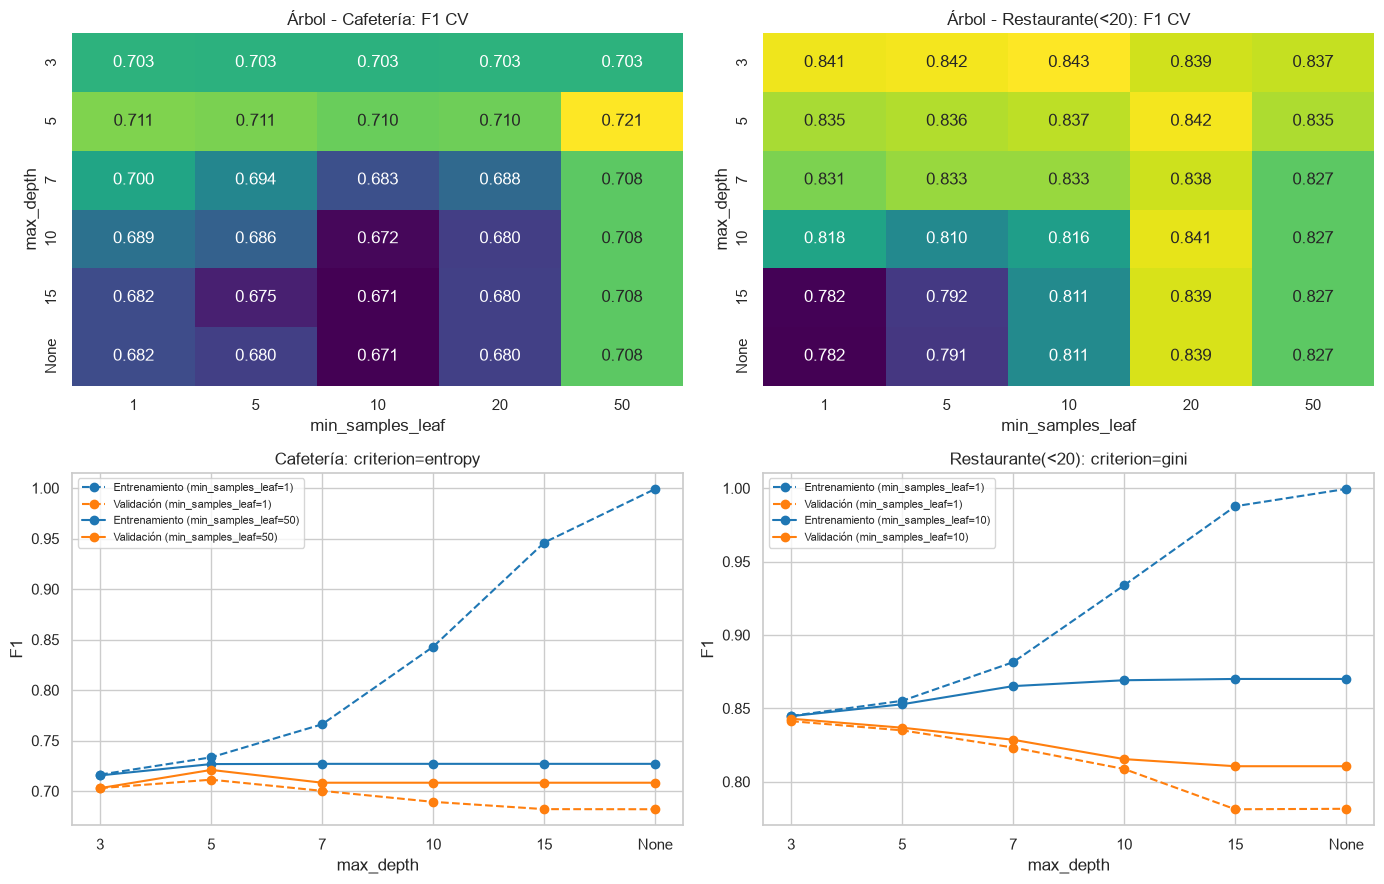

,Cafetería,Restaurante(<20)
param_modelo__criterion,,
entropy,0.7210,0.8407
gini,0.7202,0.8429
log_loss,0.7210,0.8407


In [31]:
def preparar_cv_arbol(busqueda):
    cv = pd.DataFrame(busqueda.cv_results_)
    cv["max_depth"] = cv["param_modelo__max_depth"].astype(object).where(cv["param_modelo__max_depth"].notna(), "None").astype(str)
    return cv

orden_prof = [str(v) for v in GRID_ARBOL["modelo__max_depth"]]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for j, cupon in enumerate(CUPONES):
    cv = preparar_cv_arbol(modelos[("Árbol de decisión", cupon)])

    mapa = cv.pivot_table(index="max_depth", columns="param_modelo__min_samples_leaf",
                          values="mean_test_score", aggfunc="max").loc[orden_prof]
    sns.heatmap(mapa, annot=True, fmt=".3f", cmap="viridis", ax=axes[0, j], cbar=False)
    axes[0, j].set_title(f"Árbol - {cupon}: F1 CV")
    axes[0, j].set_xlabel("min_samples_leaf")

    # Curvas con el mejor criterio: sin restricción de hojas (min_samples_leaf=1) vs. el mejor min_samples_leaf
    mejor = modelos[("Árbol de decisión", cupon)].best_params_
    for msl, estilo in [(1, "--"), (mejor["modelo__min_samples_leaf"], "-")]:
        sub = cv[(cv["param_modelo__criterion"] == mejor["modelo__criterion"]) &
                 (cv["param_modelo__min_samples_leaf"] == msl)].set_index("max_depth").loc[orden_prof]
        axes[1, j].plot(orden_prof, sub["mean_train_score"], estilo, marker="o", color="tab:blue", label=f"Entrenamiento (min_samples_leaf={msl})")
        axes[1, j].plot(orden_prof, sub["mean_test_score"], estilo, marker="o", color="tab:orange", label=f"Validación (min_samples_leaf={msl})")
    axes[1, j].set_title(f"{cupon}: criterion={mejor['modelo__criterion']}")
    axes[1, j].set_xlabel("max_depth")
    axes[1, j].set_ylabel("F1")
    axes[1, j].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Comparación de criterios (mejor F1 alcanzado con cada uno)
pd.DataFrame({cupon: pd.DataFrame(modelos[("Árbol de decisión", cupon)].cv_results_)
              .groupby("param_modelo__criterion")["mean_test_score"].max() for cupon in CUPONES}).round(4)

### 4.5 Visualización de los primeros niveles de los árboles
Se muestran los 3 primeros niveles de cada árbol óptimo. Las variables ordinales aparecen con su código numérico (posición en el orden del diccionario, empezando en 0); por ejemplo, para las frecuencias: 0 = nunca, 1 = menos de 1, 2 = 1 a 3, 3 = 4 a 8, 4 = más de 8. Las variables one-hot aparecen como `variable_valor <= 0.5` (es decir, **no** toma ese valor hacia la izquierda).

Cafetería: profundidad = 5, hojas = 24


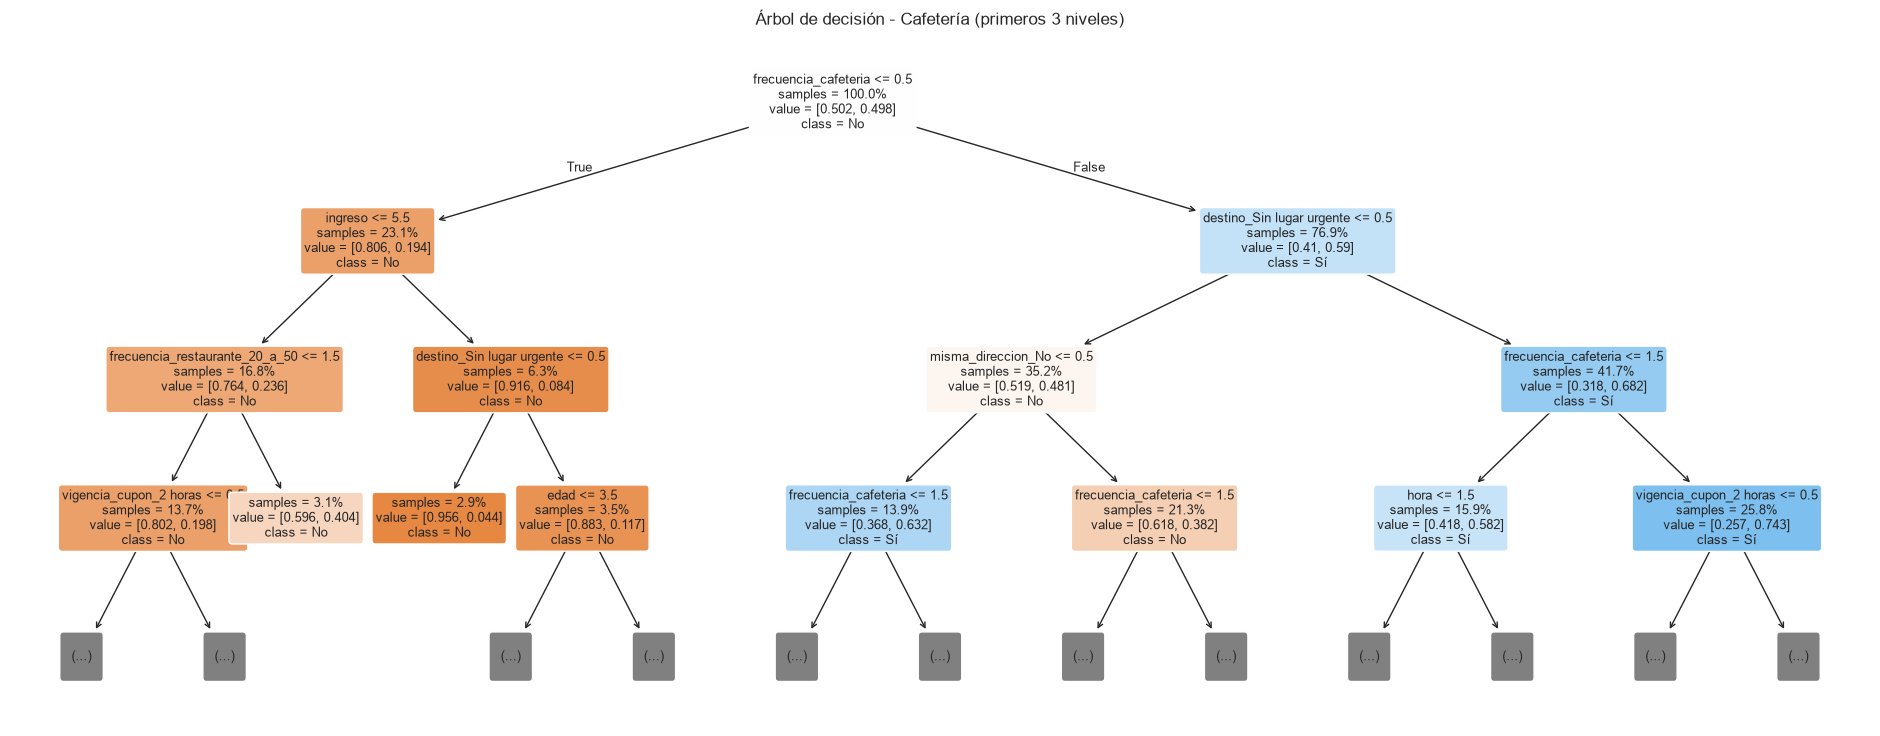

Restaurante(<20): profundidad = 3, hojas = 8


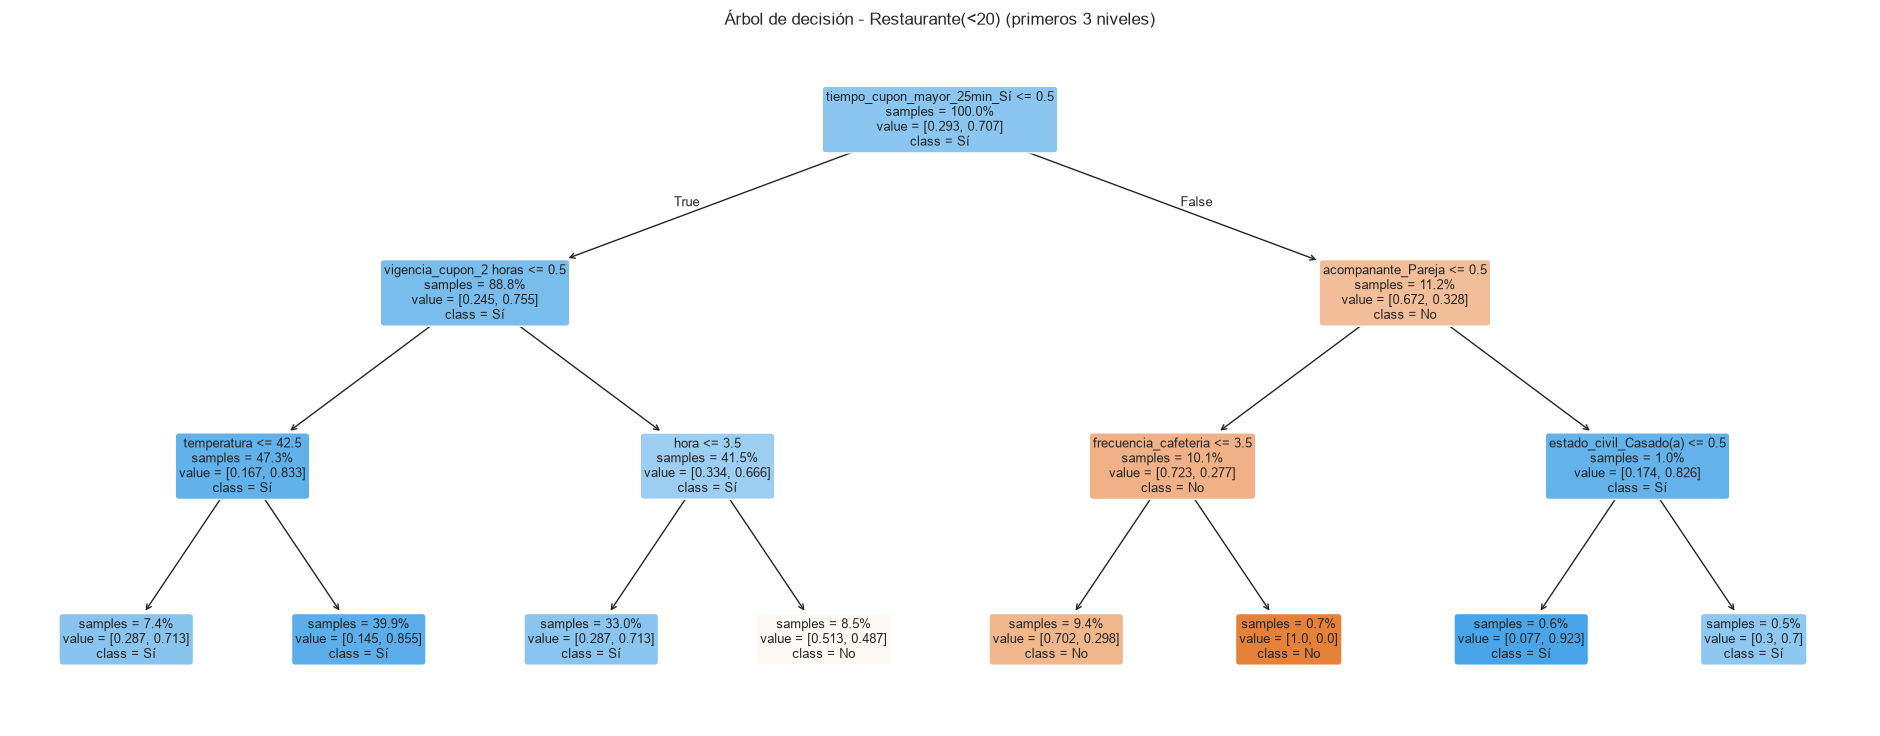

In [32]:
def nombres_variables(pipeline):
    return [n.split("__", 1)[1] for n in pipeline.named_steps["preprocesamiento"].get_feature_names_out()]

for cupon in CUPONES:
    mejor_arbol = modelos[("Árbol de decisión", cupon)].best_estimator_
    arbol = mejor_arbol.named_steps["modelo"]
    print(f"{cupon}: profundidad = {arbol.get_depth()}, hojas = {arbol.get_n_leaves()}")
    plt.figure(figsize=(24, 9))
    plot_tree(arbol, max_depth=3, feature_names=nombres_variables(mejor_arbol), class_names=["No", "Sí"],
              filled=True, rounded=True, impurity=False, proportion=True, fontsize=9)
    plt.title(f"Árbol de decisión - {cupon} (primeros 3 niveles)")
    plt.show()

### 4.6 Evaluación sobre test

===== Árbol de decisión - Cafetería (test) =====
              precision    recall  f1-score   support

          No      0.714     0.644     0.677       399
          Sí      0.674     0.741     0.706       397

    accuracy                          0.692       796
   macro avg      0.694     0.692     0.692       796
weighted avg      0.694     0.692     0.692       796

===== Árbol de decisión - Restaurante(<20) (test) =====
              precision    recall  f1-score   support

          No      0.633     0.383     0.477       162
          Sí      0.781     0.908     0.840       392

    accuracy                          0.755       554
   macro avg      0.707     0.645     0.658       554
weighted avg      0.737     0.755     0.734       554



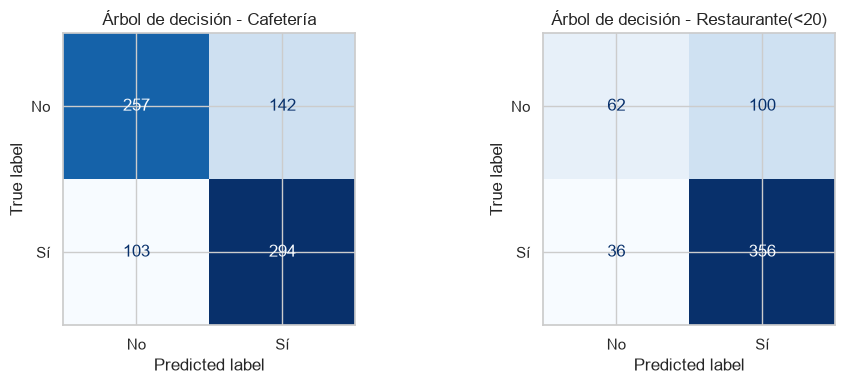

,algoritmo,precision,recall,f1,recall_No,accuracy
cupon,,,,,,
Cafetería,Árbol de decisión,0.6743,0.7406,0.7059,0.6441,0.6922
Restaurante(<20),Árbol de decisión,0.7807,0.9082,0.8396,0.3827,0.7545


In [33]:
mostrar_evaluacion("Árbol de decisión")

### 4.7 Conclusiones del árbol de decisión

| Cupón | Mejor configuración | F1 CV | F1 test | Recall "No" test | Tamaño |
|:---|:---|:---:|:---:|:---:|:---:|
| Cafetería | `entropy`, `max_depth=5`, `min_samples_leaf=50` | 0.721 | 0.706 | 0.644 | 24 hojas |
| Restaurante(<20) | `gini`, `max_depth=3`, `min_samples_leaf=10` | 0.843 | 0.840 | 0.383 | 8 hojas |

- **Los mejores árboles son poco profundos.** Las curvas de entrenamiento vs. validación (líneas punteadas, `min_samples_leaf=1`) muestran el sobreajuste típico de los árboles: con `max_depth=15` el F1 de entrenamiento llega a 0.97 (Cafetería) y 0.99 (Restaurante(<20)), mientras que el de validación cae a 0.68 y 0.78, respectivamente. Exigir un mínimo de muestras por hoja (líneas continuas) cierra esa brecha: ambos hiperparámetros actúan como regularización.
- **El criterio de división casi no importa** (diferencias ≤ 0.002 en F1). Como se esperaba, `entropy` y `log_loss` dan exactamente el mismo resultado.
- **Reglas principales (primeros niveles):**
  - **Cafetería:** la primera división es `frecuencia_cafeteria`: quienes **nunca** van a cafeterías tienden a rechazar el cupón. Luego aparecen el `destino` ("Sin lugar urgente" favorece la aceptación), el `ingreso`, la `vigencia_cupon` y la `hora`.
  - **Restaurante(<20):** la primera división es la **distancia**: si el restaurante está a más de 25 minutos, el árbol predice rechazo (salvo si viaja con su pareja). Si está cerca, predice aceptación, excepto con cupones de 2 horas en horas tardías (`hora` > 6:00 p.m., es decir, 10:00 p.m.).
- Frente a la regresión logística, el árbol tiene un desempeño muy similar en ambos cupones, con la ventaja de ser directamente interpretable como reglas.


## 5. Random Forest

### 5.1 Pipeline y espacio de búsqueda
Random Forest combina muchos árboles entrenados sobre muestras *bootstrap* de los datos y, en cada división, sobre un subconjunto aleatorio de variables. Promediar árboles poco correlacionados reduce la varianza de un árbol individual, por lo que suele generalizar mejor. Igual que con el árbol, se usa el preprocesador sin escalado.

Se exploran:
- **`n_estimators`** (número de árboles): más árboles → predicciones más estables, con rendimientos decrecientes y mayor costo computacional.
- **`max_depth`** (profundidad máxima de cada árbol).
- **`min_samples_leaf`** (mínimo de muestras por hoja).
- **`max_features`** (fracción de variables consideradas en cada división): controla qué tan distintos son los árboles entre sí. `sqrt` ≈ 8 de las 62 columnas; `0.3` ≈ 19.

In [34]:
from sklearn.ensemble import RandomForestClassifier

def crear_pipeline_rf():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador(escalar=False)),
        ("modelo", RandomForestClassifier(random_state=RANDOM_STATE)),
    ])

GRID_RF = {
    "modelo__n_estimators": [100, 300, 500],
    "modelo__max_depth": [10, 20, None],
    "modelo__min_samples_leaf": [1, 2, 5, 10],
    "modelo__max_features": ["sqrt", 0.3],
}
print("Combinaciones a evaluar por cupón:", np.prod([len(v) for v in GRID_RF.values()]), "x 5 folds")

Combinaciones a evaluar por cupón: 72 x 5 folds


### 5.2 Búsqueda de hiperparámetros: Cafetería

In [35]:
rf_cafe = buscar_hiperparametros(crear_pipeline_rf(), GRID_RF, "Cafetería", "Random Forest")
top_configuraciones(rf_cafe)

Random Forest - Cafetería
  Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}
  f1 en validación cruzada: 0.7589


,param_modelo__max_depth,param_modelo__max_features,param_modelo__min_samples_leaf,param_modelo__n_estimators,mean_test_score,std_test_score,rank_test_score
50,None,sqrt,1,500,0.758930,0.012780,1
61,None,0.3,1,300,0.758604,0.009853,2
60,None,0.3,1,100,0.756998,0.010475,3
49,None,sqrt,1,300,0.756932,0.013094,4
37,20,0.3,1,300,0.756737,0.008894,5


### 5.3 Búsqueda de hiperparámetros: Restaurante(<20)

In [36]:
rf_rest = buscar_hiperparametros(crear_pipeline_rf(), GRID_RF, "Restaurante(<20)", "Random Forest")
top_configuraciones(rf_rest)

Random Forest - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}
  f1 en validación cruzada: 0.8574


,param_modelo__max_depth,param_modelo__max_features,param_modelo__min_samples_leaf,param_modelo__n_estimators,mean_test_score,std_test_score,rank_test_score
50,None,sqrt,1,500,0.857402,0.008369,1
26,20,sqrt,1,500,0.856970,0.007825,2
49,None,sqrt,1,300,0.855513,0.004989,3
25,20,sqrt,1,300,0.855026,0.006164,4
14,10,0.3,1,500,0.854281,0.001050,5


### 5.4 Efecto de los hiperparámetros
F1 de validación cruzada en función de cada hiperparámetro, fijando los demás en su mejor valor.

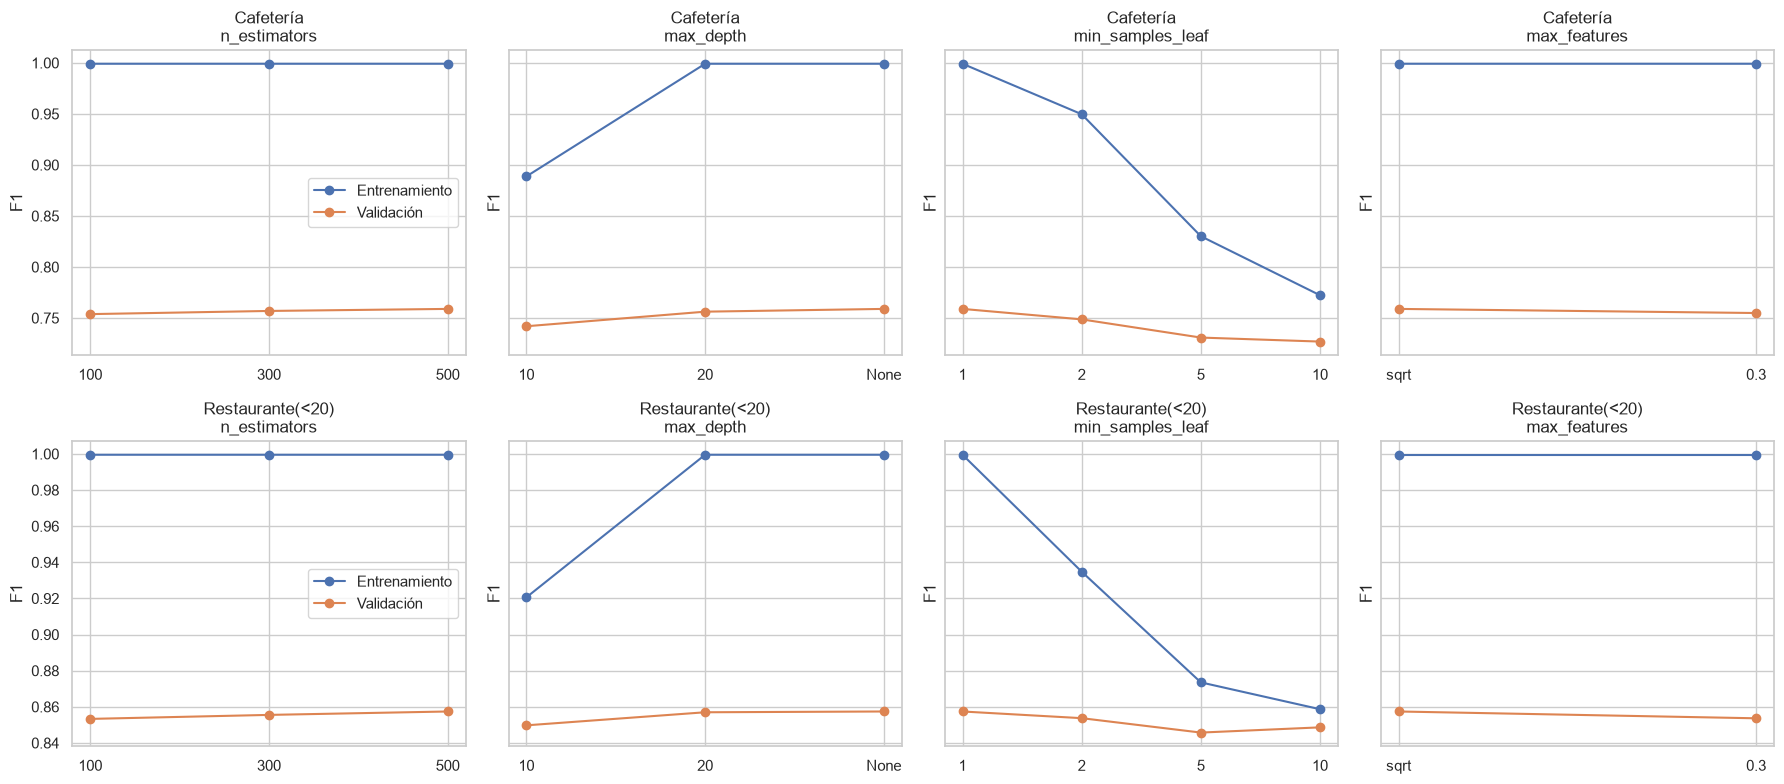

In [37]:
HIPER_RF = ["modelo__n_estimators", "modelo__max_depth", "modelo__min_samples_leaf", "modelo__max_features"]

fig, axes = plt.subplots(2, len(HIPER_RF), figsize=(18, 8), sharey="row")
for i, cupon in enumerate(CUPONES):
    busqueda = modelos[("Random Forest", cupon)]
    cv = pd.DataFrame(busqueda.cv_results_)
    for j, h in enumerate(HIPER_RF):
        filtro = np.ones(len(cv), dtype=bool)
        for otro in HIPER_RF:
            if otro != h:
                mejor = busqueda.best_params_[otro]
                col = cv[f"param_{otro}"]
                filtro &= col.isna().to_numpy() if mejor is None else (col == mejor).to_numpy()
        sub = cv[filtro]
        etiquetas = sub[f"param_{h}"].astype(object).where(sub[f"param_{h}"].notna(), "None").astype(str)
        ax = axes[i, j]
        ax.plot(etiquetas, sub["mean_train_score"], marker="o", label="Entrenamiento")
        ax.plot(etiquetas, sub["mean_test_score"], marker="o", label="Validación")
        ax.set_title(f"{cupon}\n{h.replace('modelo__', '')}")
        ax.set_ylabel("F1")
        if j == 0:
            ax.legend()
plt.tight_layout()
plt.show()

### 5.5 Evaluación sobre test

===== Random Forest - Cafetería (test) =====
              precision    recall  f1-score   support

          No      0.768     0.779     0.774       399
          Sí      0.775     0.763     0.769       397

    accuracy                          0.771       796
   macro avg      0.771     0.771     0.771       796
weighted avg      0.771     0.771     0.771       796

===== Random Forest - Restaurante(<20) (test) =====
              precision    recall  f1-score   support

          No      0.713     0.414     0.523       162
          Sí      0.793     0.931     0.857       392

    accuracy                          0.780       554
   macro avg      0.753     0.672     0.690       554
weighted avg      0.770     0.780     0.759       554



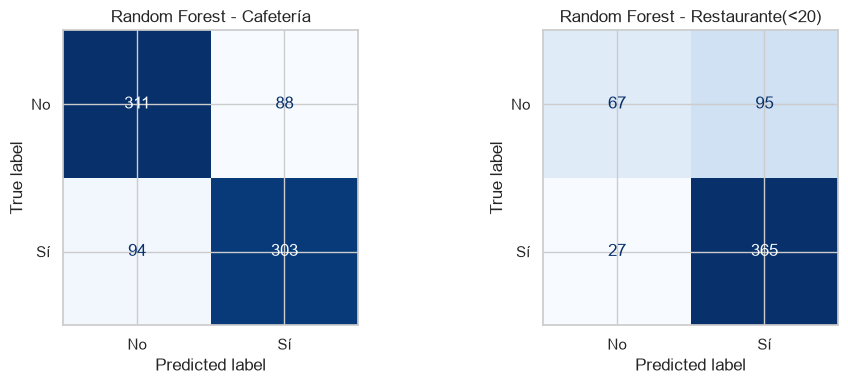

,algoritmo,precision,recall,f1,recall_No,accuracy
cupon,,,,,,
Cafetería,Random Forest,0.7749,0.7632,0.7690,0.7794,0.7714
Restaurante(<20),Random Forest,0.7935,0.9311,0.8568,0.4136,0.7798


In [38]:
mostrar_evaluacion("Random Forest")

### 5.6 Conclusiones de Random Forest

| Cupón | Mejor configuración | F1 CV | F1 test | Recall "No" test |
|:---|:---|:---:|:---:|:---:|
| Cafetería | 500 árboles, `max_depth=None`, `min_samples_leaf=1`, `max_features="sqrt"` | 0.759 | 0.769 | 0.779 |
| Restaurante(<20) | 500 árboles, `max_depth=None`, `min_samples_leaf=1`, `max_features="sqrt"` | 0.857 | 0.857 | 0.414 |

- **Es el mejor de los tres algoritmos en ambos cupones**, con una mejora especialmente clara en Cafetería (+0.06 a 0.07 de F1 frente a la regresión logística y el árbol).
- **A diferencia del árbol individual, los árboles del bosque rinden mejor sin restricción de profundidad.** Cada árbol profundo sobreajusta por separado (F1 de entrenamiento ≈ 1), pero al promediar cientos de árboles entrenados con muestras y variables distintas, la varianza se reduce y el conjunto generaliza bien. Por eso el F1 de test es igual o mayor que el de validación cruzada.
- **`n_estimators`** muestra rendimientos decrecientes: pasar de 100 a 500 árboles mejora el F1 en milésimas. El mejor valor está en el borde de la grilla (500), pero la tendencia sugiere que más árboles no cambiarían el resultado de forma relevante y sí aumentarían el costo computacional.
- **Restaurante(<20)** mantiene el mismo problema que los otros modelos: aunque el recall de "No" mejora un poco (0.41), el modelo sigue identificando menos de la mitad de los rechazos. Esto motiva la evaluación del balanceo de clases en la Actividad 6.


## 6. Balanceo de clases en Restaurante(<20)

En las actividades 3 a 5 se observó que, en Restaurante(<20), los tres modelos tienen un F1 alto para la clase "Sí" pero identifican menos de la mitad de los rechazos (recall de "No" entre 0.34 y 0.41). Esto es consistente con el desbalance de clases (~71% Sí / ~29% No): al minimizar el error global, los modelos favorecen la clase mayoritaria.

Se evalúan dos técnicas de balanceo frente a los modelos sin balancear:

1. **SMOTE** (*Synthetic Minority Over-sampling Technique*): genera ejemplos sintéticos de la clase minoritaria interpolando entre cada ejemplo y sus `k` vecinos más cercanos de la misma clase, hasta igualar el número de ejemplos de ambas clases.
2. **`class_weight="balanced"`** (como punto de comparación adicional): en lugar de crear datos, asigna a cada clase un peso inversamente proporcional a su frecuencia en la función de pérdida, de modo que equivocarse en un "No" cuesta más.

**Evitar la fuga de información:** SMOTE se integra en un `Pipeline` de `imbalanced-learn`, que aplica el sobremuestreo **solo durante el `fit`**. En la validación cruzada, los ejemplos sintéticos se generan únicamente con el *fold* de entrenamiento; los *folds* de validación y el conjunto de test conservan la distribución real de clases. Aplicar SMOTE antes de partir los datos inflaría artificialmente las métricas.

**Métrica de selección para esta actividad: F1 macro.** En un primer intento se usó el F1 de la clase "Sí" (la misma métrica de las actividades 3 a 5) y la búsqueda con SMOTE seleccionó una regresión logística con regularización tan fuerte (`C=0.001`) que predecía la misma clase para todos los conductores. La razón es que en Restaurante(<20) un modelo trivial que predice **"Sí" para todos** obtiene un F1 de "Sí" de 2·0.707/(1+0.707) ≈ **0.83**, prácticamente igual al de los modelos entrenados. Es decir, el F1 de la clase mayoritaria **premia al modelo trivial y castiga justamente lo que busca el balanceo** (sacrificar algo de recall de "Sí" a cambio de detectar más "No"). El **F1 macro** (promedio simple del F1 de ambas clases) da el mismo peso a la clase minoritaria y no favorece al modelo trivial (su F1 macro es ≈ 0.41).

Para que la comparación sea justa, las tres variantes (**sin balanceo, SMOTE y `class_weight`**) repiten la misma búsqueda de hiperparámetros de su algoritmo con F1 macro, agregando para SMOTE el número de vecinos `k_neighbors`. Además, se incluye como referencia el modelo trivial ("siempre Sí") y el porcentaje de predicciones "Sí" de cada modelo, para detectar modelos degenerados.

### 6.1 Efecto de SMOTE sobre la distribución de clases del entrenamiento

In [39]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

p_rest = particiones["Restaurante(<20)"]
X_pre = crear_preprocesador(escalar=False).fit_transform(p_rest["X_train"])
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_pre, p_rest["y_train"])

pd.DataFrame({
    "Antes de SMOTE": p_rest["y_train"].value_counts().rename({1: "Sí", 0: "No"}),
    "Después de SMOTE": pd.Series(y_res).value_counts().rename({1: "Sí", 0: "No"}),
})

,Antes de SMOTE,Después de SMOTE
acepta_cupon,,
No,648,1567
Sí,1567,1567


### 6.2 Búsqueda de hiperparámetros sin balanceo, con SMOTE y con `class_weight` (selección por F1 macro)

In [40]:
ALGORITMOS = {
    "Regresión logística": (lambda: LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), True, GRID_LR),
    "Árbol de decisión": (lambda: DecisionTreeClassifier(random_state=RANDOM_STATE), False, GRID_ARBOL),
    "Random Forest": (lambda: RandomForestClassifier(random_state=RANDOM_STATE), False, GRID_RF),
}
TECNICAS = ["Sin balanceo", "SMOTE", "class_weight"]

def ampliar_grid(grid, extra):
    grids = grid if isinstance(grid, list) else [grid]
    return [{**g, **extra} for g in grids]

def crear_variante(crear_modelo, escalar, grid, tecnica):
    pasos = [("preprocesamiento", crear_preprocesador(escalar=escalar))]
    if tecnica == "SMOTE":
        pasos.append(("smote", SMOTE(random_state=RANDOM_STATE)))
        grid = ampliar_grid(grid, {"smote__k_neighbors": [3, 5, 10]})
    elif tecnica == "class_weight":
        grid = ampliar_grid(grid, {"modelo__class_weight": ["balanced"]})
    pasos.append(("modelo", crear_modelo()))
    return ImbPipeline(pasos), grid

for nombre, (crear_modelo, escalar, grid) in ALGORITMOS.items():
    for tecnica in TECNICAS:
        pipeline, grid_t = crear_variante(crear_modelo, escalar, grid, tecnica)
        buscar_hiperparametros(pipeline, grid_t, "Restaurante(<20)", f"{nombre} | {tecnica}", scoring="f1_macro")

Regresión logística | Sin balanceo - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__C': 1, 'modelo__l1_ratio': 0, 'modelo__solver': 'saga'}
  f1_macro en validación cruzada: 0.6590


Regresión logística | SMOTE - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__C': 0.01, 'modelo__l1_ratio': 0, 'modelo__solver': 'lbfgs', 'smote__k_neighbors': 5}
  f1_macro en validación cruzada: 0.6711


Regresión logística | class_weight - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__C': 0.01, 'modelo__class_weight': 'balanced', 'modelo__l1_ratio': 0, 'modelo__solver': 'liblinear'}
  f1_macro en validación cruzada: 0.6698


Árbol de decisión | Sin balanceo - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 20}
  f1_macro en validación cruzada: 0.6868


Árbol de decisión | SMOTE - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 20, 'smote__k_neighbors': 3}
  f1_macro en validación cruzada: 0.6667


Árbol de decisión | class_weight - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__class_weight': 'balanced', 'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 20}
  f1_macro en validación cruzada: 0.6449


Random Forest | Sin balanceo - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}
  f1_macro en validación cruzada: 0.7030


Random Forest | SMOTE - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500, 'smote__k_neighbors': 3}
  f1_macro en validación cruzada: 0.7021


Random Forest | class_weight - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': 10, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}
  f1_macro en validación cruzada: 0.7066


### 6.3 Comparación sobre test
Se reportan el F1, la precisión y el recall de ambas clases, con énfasis en el **recall de la clase minoritaria "No"**, y el **F1 macro**. La primera fila corresponde al modelo trivial que predice "Sí" para todos los conductores.

In [41]:
from sklearn.dummy import DummyClassifier

def metricas_balanceo(modelo, X, y):
    y_pred = modelo.predict(X)
    return {
        "%_pred_Sí": y_pred.mean() * 100,
        "f1_Sí": f1_score(y, y_pred, zero_division=0),
        "precision_Sí": precision_score(y, y_pred, zero_division=0),
        "recall_Sí": recall_score(y, y_pred, zero_division=0),
        "recall_No": recall_score(y, y_pred, pos_label=0, zero_division=0),
        "precision_No": precision_score(y, y_pred, pos_label=0, zero_division=0),
        "f1_No": f1_score(y, y_pred, pos_label=0, zero_division=0),
        "f1_macro": f1_score(y, y_pred, average="macro", zero_division=0),
    }

trivial = DummyClassifier(strategy="constant", constant=1).fit(p_rest["X_train"], p_rest["y_train"])
filas = [{"algoritmo": "Referencia: siempre Sí", "tecnica": "-", "f1_macro_CV": np.nan,
          **metricas_balanceo(trivial, p_rest["X_test"], p_rest["y_test"])}]
for nombre in ALGORITMOS:
    for tecnica in TECNICAS:
        busqueda = modelos[(f"{nombre} | {tecnica}", "Restaurante(<20)")]
        filas.append({"algoritmo": nombre, "tecnica": tecnica, "f1_macro_CV": busqueda.best_score_,
                      **metricas_balanceo(busqueda, p_rest["X_test"], p_rest["y_test"])})
comparacion_balanceo = pd.DataFrame(filas).set_index(["algoritmo", "tecnica"]).round(4)
comparacion_balanceo

f1_macro_CV  %_pred_Sí   f1_Sí  \
algoritmo              tecnica                                        
Referencia: siempre Sí -                     NaN   100.0000  0.8288   
Regresión logística    Sin balanceo       0.6590    81.7690  0.8331   
                       SMOTE              0.6711    63.7184  0.7919   
                       class_weight       0.6698    65.5235  0.7947   
Árbol de decisión      Sin balanceo       0.6868    81.9495  0.8416   
                       SMOTE              0.6667    79.9639  0.8359   
                       class_weight       0.6449    61.5523  0.7749   
Random Forest          Sin balanceo       0.7030    83.0325  0.8568   
                       SMOTE              0.7021    81.5884  0.8555   
                       class_weight       0.7066    70.2166  0.8169   

                                     precision_Sí  recall_Sí  recall_No  \
algoritmo              tecnica                                            
Referencia: siempre Sí -                   0.7076     1.0000     0.0000   
Regresión logística    Sin balanceo        0.7770     0.8980     0.3765   
                       SMOTE               0.8357     0.7526     0.6420   
                       class_weight        0.8264     0.7653     0.6111   
Árbol de decisión      Sin balanceo        0.7841     0.9082     0.3951   
                       SMOTE               0.7878     0.8903     0.4198   
                       class_weight        0.8328     0.7245     0.6481   
Random Forest          Sin balanceo        0.7935     0.9311     0.4136   
                       SMOTE               0.7987     0.9209     0.4383   
                       class_weight        0.8201     0.8138     0.5679   

                                     precision_No   f1_No  f1_macro  
algoritmo              tecnica                                       
Referencia: siempre Sí -                   0.0000  0.0000    0.4144  
Regresión logística    Sin balanceo        0.6040  0.4639    0.6485  
                       SMOTE               0.5174  0.5730    0.6825  
                       class_weight        0.5183  0.5609    0.6778  
Árbol de decisión      Sin balanceo        0.6400  0.4885    0.6651  
                       SMOTE               0.6126  0.4982    0.6670  
                       class_weight        0.4930  0.5600    0.6674  
Random Forest          Sin balanceo        0.7128  0.5234    0.6901  
                       SMOTE               0.6961  0.5379    0.6967  
                       class_weight        0.5576  0.5627    0.6898

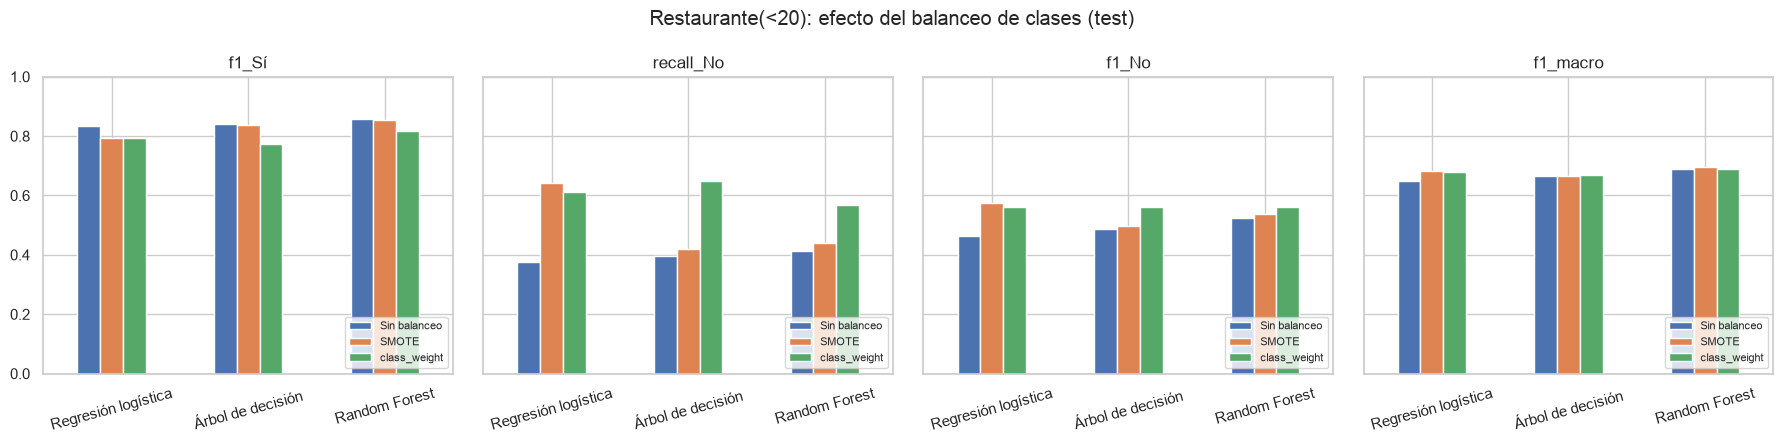

In [42]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, metrica in zip(axes, ["f1_Sí", "recall_No", "f1_No", "f1_macro"]):
    comparacion_balanceo[metrica].drop(index="Referencia: siempre Sí", level="algoritmo").unstack("tecnica")[TECNICAS].loc[list(ALGORITMOS)].plot(kind="bar", ax=ax, rot=15)
    ax.set_title(metrica)
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8, loc="lower right")
plt.suptitle("Restaurante(<20): efecto del balanceo de clases (test)")
plt.tight_layout()
plt.show()

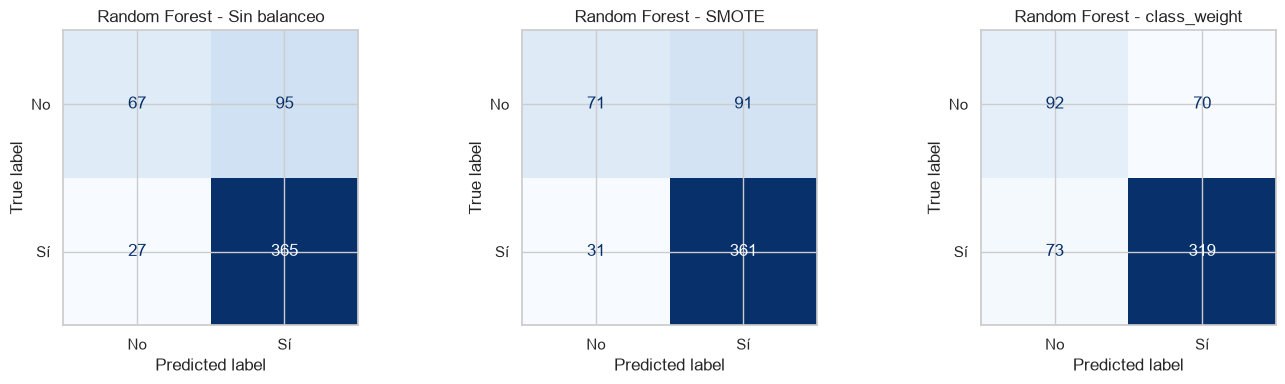

In [43]:
# Matrices de confusión de Random Forest con cada técnica
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, tecnica in zip(axes, TECNICAS):
    ConfusionMatrixDisplay.from_estimator(modelos[(f"Random Forest | {tecnica}", "Restaurante(<20)")],
                                          p_rest["X_test"], p_rest["y_test"], display_labels=["No", "Sí"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Random Forest - {tecnica}")
plt.tight_layout()
plt.show()

### 6.4 Conclusiones y recomendación sobre el balanceo de clases

| Algoritmo | Técnica | F1 "Sí" | Recall "No" | F1 macro |
|:---|:---|:---:|:---:|:---:|
| *Referencia: siempre Sí* | – | *0.829* | *0.000* | *0.414* |
| Regresión logística | Sin balanceo | 0.833 | 0.377 | 0.649 |
| | SMOTE | 0.792 | **0.642** | **0.683** |
| | class_weight | 0.795 | 0.611 | 0.678 |
| Árbol de decisión | Sin balanceo | 0.842 | 0.395 | 0.665 |
| | SMOTE | 0.836 | 0.420 | 0.667 |
| | class_weight | 0.775 | 0.648 | 0.667 |
| Random Forest | Sin balanceo | **0.857** | 0.414 | 0.690 |
| | SMOTE | 0.856 | 0.438 | **0.697** |
| | class_weight | 0.817 | 0.568 | 0.690 |

**Observaciones**
- **El F1 de la clase mayoritaria, por sí solo, es engañoso en este problema:** el modelo trivial que acepta a todos obtiene 0.829, muy cerca de los modelos entrenados (0.83-0.86), aunque no detecta ningún rechazo. Por eso es indispensable mirar también el recall de "No" y el F1 macro.
- **SMOTE produce el efecto esperado, pero su magnitud depende del algoritmo:**
  - En **regresión logística** el efecto es grande: el recall de "No" pasa de 0.38 a 0.64 (detecta casi el doble de rechazos), a cambio de bajar el F1 de "Sí" de 0.833 a 0.792. El F1 macro mejora (0.649 → 0.683).
  - En el **árbol** y en **Random Forest** la mejora es marginal (+0.02 a +0.03 en recall de "No", F1 de "Sí" prácticamente igual). En validación cruzada, Random Forest con SMOTE incluso obtiene un F1 macro ligeramente menor que sin balanceo (0.702 vs. 0.703), por lo que la diferencia en test está dentro del ruido.
- **`class_weight="balanced"`** logra un aumento mayor del recall de "No" en los modelos de árboles (0.57-0.65), pero con una caída más fuerte del F1 de "Sí", sin mejorar el F1 macro. Es decir, ninguna técnica mejora **ambas** métricas a la vez: se trata de un **intercambio** entre detectar rechazos y no perder aceptaciones.
- Una posible explicación de que SMOTE aporte poco a los árboles es que interpola entre registros en el espacio codificado: genera valores intermedios en variables ordinales y one-hot (p. ej. 0.4 en una variable binaria) que no corresponden a conductores reales. Los árboles, además, ya pueden aislar regiones de la clase minoritaria sin datos sintéticos. Una alternativa diseñada para variables categóricas es `SMOTENC`.

**Recomendación**
- Para el **mejor modelo (Random Forest)**, **no se recomienda aplicar SMOTE**: la mejora en recall de "No" es pequeña, no es consistente entre validación cruzada y test, y agrega complejidad y datos sintéticos poco realistas.
- Sin embargo, la decisión depende del **costo de cada error para Ruta Alpes**. Si la prioridad es **no molestar** a los conductores con notificaciones irrelevantes (es decir, detectar los rechazos), conviene una técnica de balanceo: SMOTE en regresión logística o `class_weight` en Random Forest elevan el recall de "No" a 0.57-0.64 a costa de mostrar menos cupones que sí se habrían aceptado. Otra alternativa, sin reentrenar, es ajustar el **umbral de decisión** del modelo según ese costo.


## 7. Tabla comparativa de los modelos

Se resume el desempeño sobre **test** de los tres algoritmos (seleccionados con F1 en las actividades 3 a 5) para cada tipo de cupón. Las métricas principales son **precisión, recall y F1 de la clase "Sí"** (aceptar el cupón); se agregan el recall de "No" y la exactitud como apoyo. Como referencia se incluye el modelo trivial que predice "Sí" para todos los conductores, que es el mínimo que un modelo útil debe superar.

In [44]:
ref = []
for cupon in CUPONES:
    p = particiones[cupon]
    y_pred = np.ones(len(p["y_test"]), dtype=int)
    ref.append({"algoritmo": "Referencia: siempre Sí", "cupon": cupon,
                "precision": precision_score(p["y_test"], y_pred), "recall": 1.0,
                "f1": f1_score(p["y_test"], y_pred), "recall_No": 0.0,
                "accuracy": accuracy_score(p["y_test"], y_pred)})

ORDEN_ALGORITMOS = ["Referencia: siempre Sí", "Regresión logística", "Árbol de decisión", "Random Forest"]
tabla_comparativa = (pd.DataFrame(ref + resultados)
                     .set_index(["cupon", "algoritmo"])
                     .loc[[(c, a) for c in CUPONES for a in ORDEN_ALGORITMOS]]
                     .round(3))
tabla_comparativa

precision  recall     f1  recall_No  \
cupon            algoritmo                                                     
Cafetería        Referencia: siempre Sí      0.499   1.000  0.666      0.000   
                 Regresión logística         0.689   0.708  0.698      0.682   
                 Árbol de decisión           0.674   0.741  0.706      0.644   
                 Random Forest               0.775   0.763  0.769      0.779   
Restaurante(<20) Referencia: siempre Sí      0.708   1.000  0.829      0.000   
                 Regresión logística         0.769   0.911  0.834      0.340   
                 Árbol de decisión           0.781   0.908  0.840      0.383   
                 Random Forest               0.793   0.931  0.857      0.414   

                                         accuracy  
cupon            algoritmo                         
Cafetería        Referencia: siempre Sí     0.499  
                 Regresión logística        0.695  
                 Árbol de decisión          0.692  
                 Random Forest              0.771  
Restaurante(<20) Referencia: siempre Sí     0.708  
                 Regresión logística        0.744  
                 Árbol de decisión          0.755  
                 Random Forest              0.780

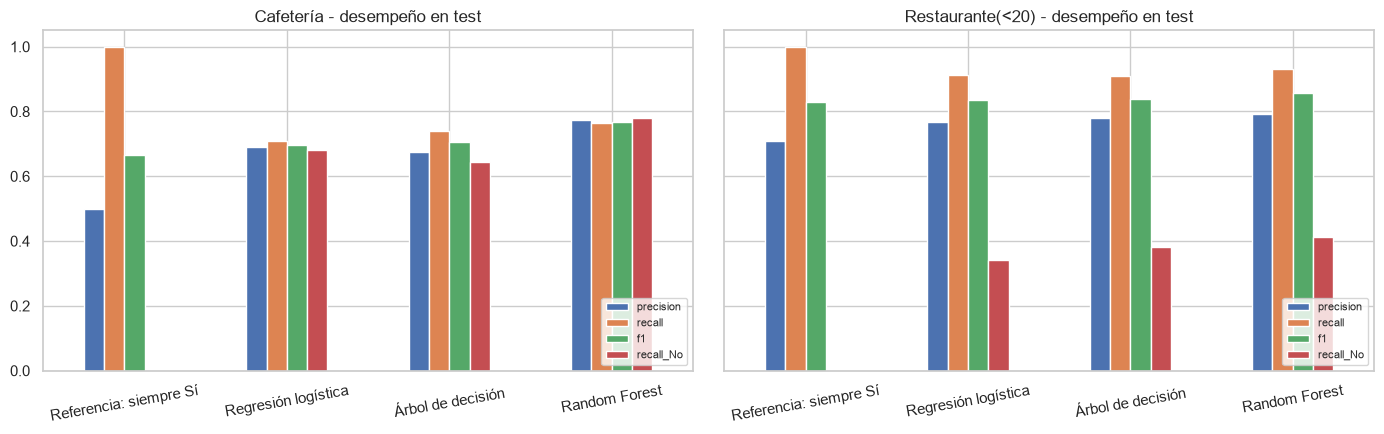

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, cupon in zip(axes, CUPONES):
    tabla_comparativa.loc[cupon][["precision", "recall", "f1", "recall_No"]].plot(kind="bar", ax=ax, rot=10)
    ax.set_title(f"{cupon} - desempeño en test")
    ax.set_xlabel("")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### 7.1 Selección del mejor modelo por tipo de cupón

**Cafetería → Random Forest.** Es claramente superior en las tres métricas: F1 = 0.769 frente a 0.698 (regresión logística) y 0.706 (árbol), con precisión y recall equilibrados (≈ 0.77) y el mejor recall de "No" (0.78). La mejora también aparece en validación cruzada (0.759 vs. 0.707 y 0.721), por lo que no es un efecto de la partición. Supera ampliamente al modelo trivial (F1 = 0.666).

**Restaurante(<20) → Random Forest.** Obtiene el mejor F1 (0.857), la mejor precisión (0.794) y el mejor recall (0.931) de "Sí", y también el mayor recall de "No" (0.414) de los tres algoritmos sin balancear. Sin embargo, las diferencias con los otros modelos son más pequeñas (≈ 0.02 de F1) y la ventaja sobre el modelo trivial (F1 = 0.829) es modesta: en este cupón, la mayor parte del F1 se explica por la alta tasa de aceptación. Por eso, como se discutió en la Actividad 6, el valor real del modelo está en identificar los rechazos, donde aún tiene margen de mejora.

**Consideraciones adicionales**
- **Interpretabilidad:** el árbol de decisión es el modelo más fácil de explicar al negocio (8 hojas en Restaurante(<20)) y su desempeño en ese cupón está a solo 0.017 de F1 del Random Forest. Si Ruta Alpes necesitara reglas explícitas y auditables, sería una alternativa razonable para ese cupón.
- **Costo computacional:** Random Forest con 500 árboles es más pesado de entrenar, pero la predicción para un solo conductor en tiempo real sigue siendo del orden de milisegundos.

Los modelos seleccionados para las predicciones finales (Actividad 10) son los **Random Forest** de cada cupón, sin técnicas de balanceo.

In [46]:
MEJORES_MODELOS = {cupon: modelos[("Random Forest", cupon)].best_estimator_ for cupon in CUPONES}
MEJORES_MODELOS

{'Cafetería': Pipeline(steps=[('preprocesamiento',
                  ColumnTransformer(transformers=[('ordinales',
                                                   Pipeline(steps=[('imputar',
                                                                    SimpleImputer(strategy='most_frequent')),
                                                                   ('codificar',
                                                                    OrdinalEncoder(categories=[['7:00 '
                                                                                                'a.m.',
                                                                                                '10:00 '
                                                                                                'a.m.',
                                                                                                '2:00 '
                                                                                              

## 8. Variables más relevantes

Se usan dos enfoques complementarios:

1. **Importancia por permutación sobre el Random Forest (mejor modelo):** mide cuánto empeora el desempeño en test cuando se desordenan aleatoriamente los valores de una variable, rompiendo su relación con la etiqueta. Se calcula sobre las **variables originales** (antes del one-hot), porque el pipeline completo recibe los datos crudos; así, por ejemplo, `ocupacion` se evalúa como una sola variable en lugar de 25 columnas. Se prefiere a la importancia por impureza del Random Forest porque esta última se calcula sobre el entrenamiento y tiende a sobrevalorar variables con muchas categorías. Como métrica se usa el **F1 macro**, para que la importancia refleje tanto la detección de aceptaciones como de rechazos.
2. **Coeficientes de la regresión logística:** como las variables están escaladas, la magnitud del coeficiente indica su peso relativo y el **signo indica la dirección**: positivo → aumenta la probabilidad de aceptar, negativo → la disminuye. Esto complementa la importancia por permutación, que no indica dirección.

### 8.1 Importancia por permutación (Random Forest)

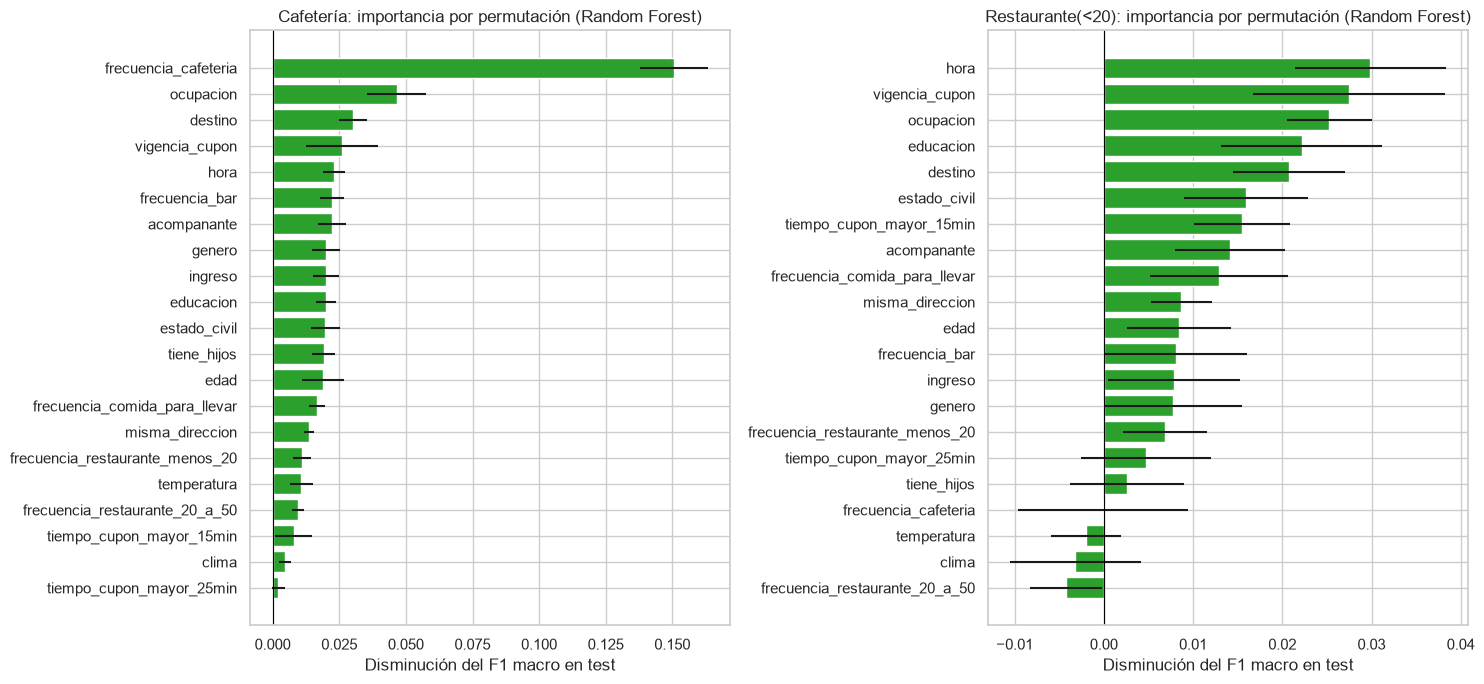

,Cafetería,Restaurante(<20)
frecuencia_cafeteria,0.1506,-0.0001
ocupacion,0.0466,0.0253
destino,0.0302,0.0208
vigencia_cupon,0.0260,0.0275
hora,0.0231,0.0299
frecuencia_bar,0.0224,0.0081
acompanante,0.0221,0.0141
genero,0.0201,0.0078
ingreso,0.0201,0.0079
educacion,0.0200,0.0222


In [47]:
from sklearn.inspection import permutation_importance

importancias = {}
for cupon in CUPONES:
    p = particiones[cupon]
    r = permutation_importance(MEJORES_MODELOS[cupon], p["X_test"], p["y_test"], scoring="f1_macro",
                               n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    importancias[cupon] = pd.DataFrame({"importancia": r.importances_mean, "std": r.importances_std},
                                       index=p["X_test"].columns).sort_values("importancia", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, cupon in zip(axes, CUPONES):
    imp = importancias[cupon].iloc[::-1]
    ax.barh(imp.index, imp["importancia"], xerr=imp["std"], color="tab:green")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{cupon}: importancia por permutación (Random Forest)")
    ax.set_xlabel("Disminución del F1 macro en test")
plt.tight_layout()
plt.show()

pd.concat({c: imp["importancia"] for c, imp in importancias.items()}, axis=1).round(4).sort_values(CUPONES[0], ascending=False)

### 8.2 Coeficientes de la regresión logística

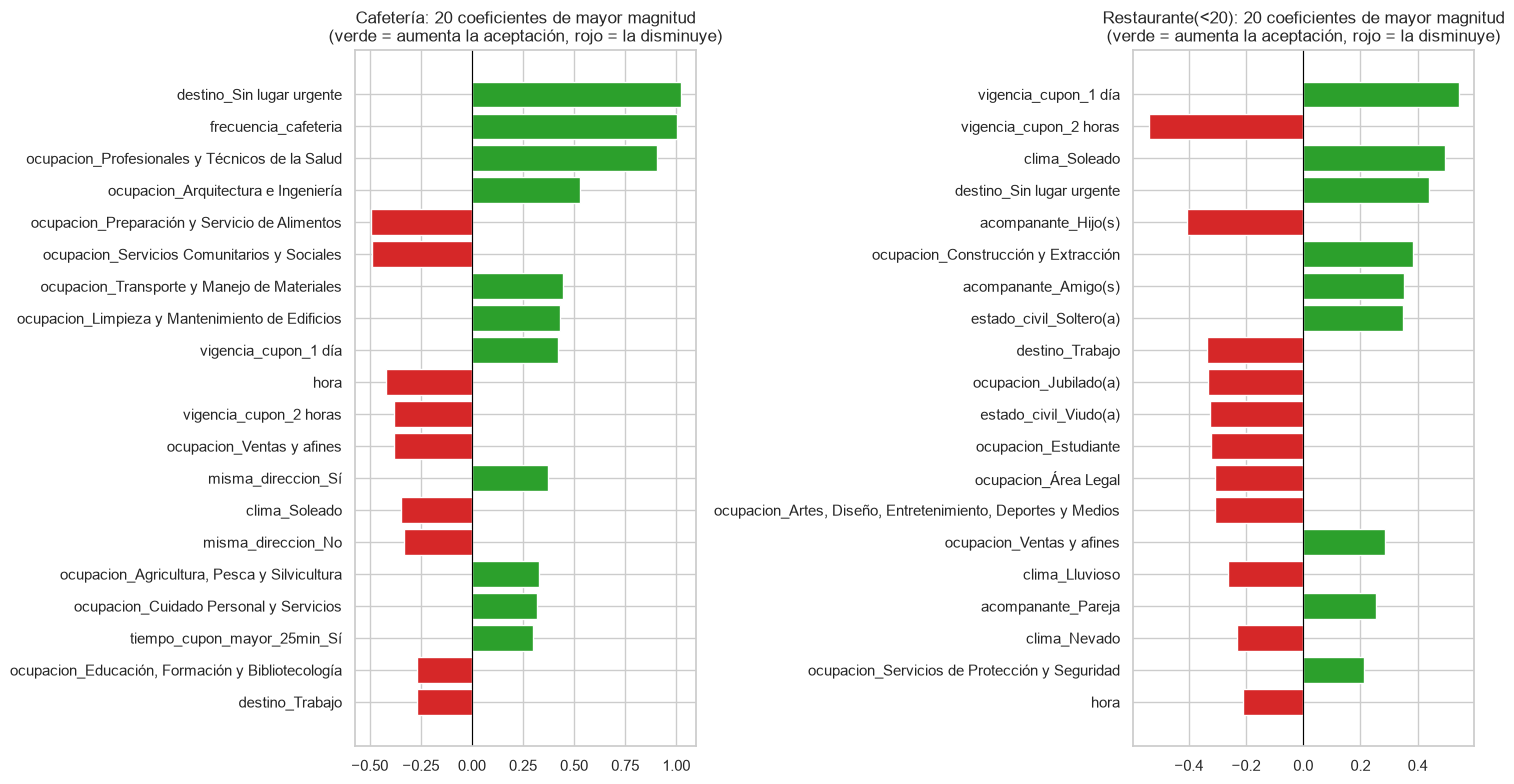

In [48]:
coeficientes = {}
for cupon in CUPONES:
    modelo_lr = modelos[("Regresión logística", cupon)].best_estimator_
    coeficientes[cupon] = pd.Series(modelo_lr.named_steps["modelo"].coef_[0], index=nombres_variables(modelo_lr))

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for ax, cupon in zip(axes, CUPONES):
    coef = coeficientes[cupon]
    top = coef.reindex(coef.abs().sort_values(ascending=False).index[:20]).iloc[::-1]
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "tab:green", "tab:red"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{cupon}: 20 coeficientes de mayor magnitud\n(verde = aumenta la aceptación, rojo = la disminuye)")
plt.tight_layout()
plt.show()

### 8.3 Dos efectos que afectan la interpretación de las importancias

**a) Las variables de perfil identifican a cada conductor.** Los datos provienen de una encuesta en la que cada persona respondió varios escenarios. Al combinar las variables demográficas y de hábitos se obtiene prácticamente un "identificador" de cada conductor. Como la partición train/test es aleatoria por filas, un mismo conductor aparece en ambos conjuntos, y un modelo flexible como Random Forest puede aprender **las preferencias individuales** de cada persona.

**b) Las variables de contexto están entrelazadas por el diseño de la encuesta.** Por ejemplo, en Restaurante(<20) los cupones a más de 25 minutos se ofrecieron casi exclusivamente en días lluviosos o nevados. Cuando dos variables cargan información similar, la importancia por permutación se **reparte** entre ellas (al desordenar una, el modelo se apoya en la otra), y ambas pueden aparecer como poco importantes.

In [49]:
VARS_PERFIL = ["genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso",
               "frecuencia_bar", "frecuencia_cafeteria", "frecuencia_comida_para_llevar",
               "frecuencia_restaurante_menos_20", "frecuencia_restaurante_20_a_50"]

for cupon in CUPONES:
    p = particiones[cupon]
    perfiles_train = set(map(tuple, p["X_train"][VARS_PERFIL].astype(str).values))
    perfiles_test = p["X_test"][VARS_PERFIL].astype(str).apply(tuple, axis=1)
    n_perfiles = datos_limpios[cupon].groupby(VARS_PERFIL, dropna=False).ngroups
    print(f"{cupon}: {n_perfiles} perfiles distintos en {len(datos_limpios[cupon])} registros "
          f"(~{len(datos_limpios[cupon]) / n_perfiles:.1f} escenarios por perfil)")
    print(f"  Registros de test cuyo perfil también está en train: {perfiles_test.isin(perfiles_train).mean() * 100:.1f}%")

perfiles_datos = set(map(tuple, datos[VARS_PERFIL].astype(str).values))
print(f"Datos de prueba (sin etiqueta) con un perfil presente en los datos etiquetados: "
      f"{prueba[VARS_PERFIL].astype(str).apply(tuple, axis=1).isin(perfiles_datos).sum()} de {len(prueba)}")

Cafetería: 565 perfiles distintos en 3979 registros (~7.0 escenarios por perfil)
  Registros de test cuyo perfil también está en train: 100.0%
Restaurante(<20): 567 perfiles distintos en 2769 registros (~4.9 escenarios por perfil)
  Registros de test cuyo perfil también está en train: 99.6%
Datos de prueba (sin etiqueta) con un perfil presente en los datos etiquetados: 20 de 20


In [50]:
# Distancia > 25 min según el clima, en Restaurante(<20)
pd.crosstab(datos_limpios["Restaurante(<20)"]["clima"], datos_limpios["Restaurante(<20)"]["tiempo_cupon_mayor_25min"],
            normalize="index").round(3)

tiempo_cupon_mayor_25min,No,Sí
clima,,
Lluvioso,0.491,0.509
Nevado,0.495,0.505
Soleado,0.985,0.015


### 8.4 Conclusiones: variables más relevantes por tipo de cupón

**Cafetería**
- **`frecuencia_cafeteria` es, con diferencia, la variable más importante** (su permutación reduce el F1 macro en ~0.15, más de tres veces que cualquier otra). En la regresión logística tiene uno de los dos coeficientes positivos más grandes: **quien ya frecuenta cafeterías acepta el cupón**. Es coherente con la primera división del árbol (quienes nunca van tienden a rechazar).
- Le siguen el **`destino`** ("Sin lugar urgente" es el coeficiente positivo más alto: sin prisa, el conductor está dispuesto a desviarse), la **`vigencia_cupon`** (1 día ↑, 2 horas ↓), la **`hora`** (coeficiente negativo: la aceptación cae a medida que avanza el día, lo que tiene sentido para el café), el **`acompanante`** y la **`ocupacion`**.
- Las variables demográficas (`genero`, `ingreso`, `edad`, `estado_civil`, `tiene_hijos`) tienen importancias similares entre sí (~0.02). Por sí solas casi no cambian la tasa de aceptación (ver 1.7), por lo que su importancia en Random Forest se explica principalmente por el efecto (a): **en conjunto permiten reconocer al conductor**.

**Restaurante(<20)**
- No hay una variable dominante: la importancia está repartida entre variables de **contexto del viaje**: `hora`, `vigencia_cupon`, `destino`, `tiempo_cupon_mayor_15min` y `acompanante`, junto con `ocupacion`, `educacion` y `estado_civil`.
- En la regresión logística, los mayores coeficientes son de contexto: **vigencia de 1 día (+)** vs. **2 horas (−)**, **clima soleado (+)**, **sin lugar urgente (+)**, **ir al trabajo (−)** y **viajar con hijos (−)** frente a viajar con amigos (+).
- La **distancia > 25 min**, que era la variable con mayor diferencia en la tasa de aceptación (1.7) y la primera división del árbol, aparece con importancia por permutación baja. Esto **no significa que sea irrelevante**: por el efecto (b), su información es en gran parte redundante con el clima, la hora y el destino, y el Random Forest puede reemplazarla con esas variables.
- `frecuencia_restaurante_menos_20` tiene poca importancia, a diferencia de lo que pasa con la frecuencia de cafetería en el otro cupón: **un restaurante económico es atractivo para casi todos, y lo que decide es si el momento y el lugar son convenientes**.

**Diferencia entre cupones:** la aceptación del cupón de **Cafetería depende sobre todo del hábito del conductor** (si ya va a cafeterías), mientras que la de **Restaurante(<20) depende sobre todo del contexto del viaje** (distancia, clima, hora, vigencia, destino). Una posible explicación de que Random Forest supere a los otros modelos por un margen mucho mayor en Cafetería es que allí la decisión depende más de las preferencias individuales del conductor, que un modelo flexible puede aprender al reconocer su perfil (efecto (a)). Comprobarlo requeriría evaluar con conductores que no estén en el entrenamiento (por ejemplo, con una partición por grupos).


## 9. Análisis de resultados

### 9.1 ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?

**Cafetería: pesa más el hábito del conductor.**
- La variable más relacionada es **`frecuencia_cafeteria`**. Su permutación reduce el F1 macro del Random Forest en ~0.15, más de tres veces que cualquier otra variable. En la exploración, la tasa de aceptación cambia unos 50 puntos porcentuales entre quienes nunca van a cafeterías y quienes van con frecuencia. Quien ya tiene el hábito acepta el cupón.
- Del contexto influyen:
  - el **destino**: "sin lugar urgente" tiene el coeficiente positivo más alto de la regresión logística;
  - la **vigencia**: 1 día favorece, 2 horas desfavorece;
  - la **hora**: la aceptación cae a medida que avanza el día;
  - el **acompañante**.
- Del perfil influyen la **ocupación**, la **edad** y el **ingreso**.

**Restaurante(<20): pesa más el contexto del viaje.**
- La importancia está repartida entre variables de contexto: **distancia** (más de 25 min reduce la aceptación en ~43 puntos porcentuales y es la primera división del árbol), **hora**, **vigencia del cupón**, **clima** (soleado ↑), **destino** (sin lugar urgente ↑, trabajo ↓) y **acompañante** (con amigos ↑, con hijos ↓).
- Del perfil aparecen la ocupación, la educación y el estado civil, con menor peso.
- La frecuencia de visita a este tipo de restaurante pesa poco. Un restaurante económico le interesa a casi todos, y lo que decide es si **el momento y el lugar son convenientes**.

### 9.2 ¿Existen variables que podrían ser redundantes o poco informativas?

Sí:
- **Eliminadas en la preparación:**
  - `vehiculo` (>99% de nulos);
  - `tiempo_cupon_mayor_5min` (constante);
  - `direccion_opuesta` (complemento exacto de `misma_direccion`).
- **`temperatura`** está casi determinada por `clima`. Lluvioso siempre es 55°F y nevado siempre 30°F, así que solo agrega información en días soleados. Su importancia por permutación es baja en Cafetería y nula o negativa en Restaurante(<20).
- **`tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min`** están anidadas: juntas forman una sola escala de distancia de 3 niveles. Además, la distancia de más de 25 min se ofreció casi exclusivamente con lluvia o nieve (51%, frente a 1.5% con sol). Por el diseño de la encuesta, distancia, clima, hora y destino cargan información parcialmente redundante. Por eso la importancia por permutación de la distancia sale baja, aunque individualmente sea muy informativa.
- **Poco informativas para cada cupón:**
  - las frecuencias de los **otros** establecimientos (bar, restaurante 20-50);
  - `genero` y `tiene_hijos`, que solas cambian la tasa de aceptación en menos de 3 puntos porcentuales en ambos cupones.
  - En Restaurante(<20), `clima`, `temperatura` y `frecuencia_restaurante_20_a_50` tienen importancia por permutación cercana a cero o negativa.
- Las variables demográficas tienen una importancia moderada en el Random Forest. Pero gran parte de ese peso parece venir de que, **combinadas, identifican al conductor**, y no de un efecto propio (ver 8.3 y 9.8).

### 9.3 ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿a qué atribuye esa diferencia?

Sí, en tres aspectos:

1. **Nivel de F1.**
   - Restaurante(<20) tiene un F1 de "Sí" más alto (0.83-0.86) que Cafetería (0.70-0.77), pero eso **no significa que sea un problema más fácil**. Se debe a la distribución de clases: el 71% acepta, así que un modelo trivial que dice "Sí" a todos ya obtiene 0.829.
   - En Cafetería, con clases balanceadas, el modelo trivial obtiene 0.666.
   - Medido como mejora sobre esa referencia, los modelos aportan bastante más en Cafetería (+0.10 de F1) que en Restaurante(<20) (+0.03).
2. **Comportamiento por clase.**
   - En Cafetería los modelos son equilibrados: precisión, recall y recall de "No" están alrededor de 0.70-0.78.
   - En Restaurante(<20) todos los modelos favorecen la clase mayoritaria: recall de "Sí" mayor a 0.9, pero recall de "No" de solo 0.34-0.41. Es el efecto del desbalance (ver 9.4).
3. **Diferencia entre algoritmos.**
   - En Cafetería, Random Forest supera claramente a la regresión logística y al árbol (+0.06-0.07 de F1).
   - En Restaurante(<20) los tres están a menos de 0.025 de diferencia.

**Atribución:**
- La aceptación de **Cafetería depende de un rasgo estable del conductor**, su hábito, y de **preferencias individuales**. Un modelo flexible como Random Forest puede capturarlas combinando variables de perfil. Como los mismos conductores aparecen en entrenamiento y test, incluso puede "reconocerlos".
- La de **Restaurante(<20) depende de condiciones del viaje**: distancia, clima, hora, vigencia. Esas condiciones generan reglas relativamente simples, que hasta un árbol de 3 niveles captura. Por eso hay poco margen para que un modelo más complejo marque diferencia.

### 9.4 ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo? Justifique considerando tanto el F1-score general como el recall de la clase minoritaria.

**Depende del algoritmo, y para el mejor modelo (Random Forest) la mejora no es significativa.**

| Algoritmo | F1 "Sí" sin → con SMOTE | Recall "No" sin → con SMOTE | F1 macro sin → con SMOTE |
|:---|:---:|:---:|:---:|
| Regresión logística | 0.833 → 0.792 | 0.377 → **0.642** | 0.649 → **0.683** |
| Árbol de decisión | 0.842 → 0.836 | 0.395 → 0.420 | 0.665 → 0.667 |
| Random Forest | 0.857 → 0.856 | 0.414 → 0.438 | 0.690 → 0.697 |

- **En regresión logística, SMOTE sí mejora el modelo:** casi duplica la detección de rechazos y sube el F1 macro, a costa de bajar el F1 de "Sí" en 0.04.
- **En el árbol y en Random Forest la mejora es marginal** (+0.02-0.03 en recall de "No"). En validación cruzada, Random Forest con SMOTE incluso queda ligeramente por debajo de la versión sin balancear (F1 macro 0.702 vs. 0.703). Por eso la diferencia en test no se puede distinguir del ruido.
- **Ninguna técnica (SMOTE ni `class_weight`) mejora a la vez el F1 de "Sí" y el recall de "No".** Lo que hacen es mover el punto de equilibrio entre ambos errores.

**Por qué el F1 general por sí solo es engañoso.** El modelo trivial "siempre Sí" obtiene F1 = 0.829, casi igual que los modelos entrenados, sin detectar ningún rechazo. De hecho, al seleccionar hiperparámetros con el F1 de "Sí", la búsqueda con SMOTE llegó a elegir un modelo degenerado que predecía una sola clase. Por eso la comparación se hizo seleccionando con F1 macro.

**Recomendación:**
- No aplicar SMOTE al modelo final de Random Forest. Agrega complejidad y datos sintéticos poco realistas: interpola valores intermedios en variables categóricas codificadas. Y no ofrece una ganancia consistente.
- Si para Ruta Alpes es prioritario **no molestar** a los conductores que van a rechazar, conviene más una técnica que mueva ese equilibrio: `class_weight`, SMOTE con regresión logística o ajustar el umbral de decisión. Esa decisión debe basarse en el costo relativo de cada tipo de error para el negocio.

### 9.5 A partir de alguno de los modelos de árbol o Random Forest, describa, en términos de reglas o de importancia de variables, las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de este tipo de interpretación.

**Reglas de los árboles de decisión (sección 4.5)**

*Restaurante(<20)* (árbol de profundidad 3, 8 hojas):
- **Si el restaurante está a más de 25 minutos → rechaza**, salvo que viaje con su pareja.
- **Si está a menos de 25 minutos:**
  - con vigencia de **1 día → acepta**;
  - con vigencia de **2 horas → acepta durante el día, pero rechaza a las 10:00 p.m.**

*Cafetería* (profundidad 5, 24 hojas):
- **Si nunca va a cafeterías → rechaza.** Todas las hojas de esa rama predicen "No". Con ingresos de $75.000 o más, el rechazo es casi total: menos del 10% acepta.
- **Si va a cafeterías y no tiene un lugar urgente al cual llegar → acepta.** La única excepción es quien va menos de una vez al mes y recibe un cupón de 2 horas a partir de las 2:00 p.m..
- **Si va a cafeterías pero se dirige a casa o al trabajo**, la decisión depende de la conveniencia:
  - si el establecimiento está **en la misma dirección**, acepta quien va al menos 1 vez al mes, o quien va al trabajo;
  - si está **en otra dirección**, solo acepta quien va al menos 1 vez al mes y recibe un cupón de **1 día**.

**Importancia de variables (Random Forest, sección 8):** confirma estas reglas. En Cafetería domina la frecuencia de visita; en Restaurante(<20) dominan la hora, la vigencia, el destino y la distancia.

**Utilidad:**
- Las reglas se traducen directamente a decisiones de negocio y se pueden explicar a personas no técnicas. Por ejemplo: "no ofrecer el cupón de restaurante si queda a más de 25 minutos" o "priorizar cupones de cafetería para conductores que ya frecuentan cafeterías y viajan sin prisa".
- Permiten **auditar** el modelo: verificar que las decisiones tengan sentido y detectar si dependen de variables sensibles. Por ejemplo, el árbol de Cafetería usa `genero` en una de sus divisiones finales.

**Limitaciones:**
- Un solo árbol es **inestable**: pequeños cambios en los datos pueden cambiar las divisiones. Además, solo describe el modelo de menor desempeño.
- El Random Forest, que es el más preciso, combina 500 árboles, y **no se puede resumir en reglas**.
- La importancia por permutación dice **cuánto** influye una variable, pero **no en qué dirección**. Además, **se reparte entre variables correlacionadas**, como la distancia y el clima, y subestima a las dos.
- Estas interpretaciones muestran **asociaciones aprendidas de los datos, no relaciones causales**. Que una ocupación tenga un coeficiente alto no significa que la ocupación *cause* la aceptación.

### 9.6 ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?

Una posible arquitectura:

1. **Perfil del conductor (fuera de línea):** las variables de hábitos y perfil se capturan al registrarse en la app y se actualizan periódicamente, idealmente con su comportamiento real (cupones aceptados, visitas).
2. **Contexto en tiempo real:**
   - la app ya conoce el **destino**, la **hora**, el **clima** (vía API) y si hay acompañantes;
   - para cada establecimiento con cupón cercano a la ruta, calcula la **distancia en minutos** y si queda en la **misma dirección**.
3. **Puntuación:**
   - para cada cupón candidato, el pipeline entrenado (preprocesamiento y modelo, ya serializado con `joblib`) calcula la **probabilidad de aceptación**;
   - la predicción de un Random Forest para un conductor toma milisegundos, por lo que es viable en tiempo real.
4. **Decisión:**
   - se muestra el cupón con mayor probabilidad (o mayor valor esperado: probabilidad × beneficio para el comercio), **solo si supera un umbral**;
   - el umbral se calibra según el costo de molestar al conductor: un umbral más alto implica menos notificaciones, pero más relevantes.
5. **Seguridad vial:** la notificación debería mostrarse en momentos seguros (vehículo detenido, o con interacción por voz) y con un límite de frecuencia.
6. **Retroalimentación y monitoreo:**
   - cada aceptación o rechazo se registra como nueva etiqueta para reentrenar el modelo periódicamente;
   - se monitorea si la distribución de los datos cambia (por ejemplo, nuevos usuarios o nuevas zonas);
   - se puede validar el impacto real con pruebas A/B.

Una consideración importante: los modelos se evaluaron con conductores que ya estaban en el entrenamiento (sección 8.3). Para **usuarios nuevos** se necesitaría una estrategia de arranque en frío, por ejemplo un modelo basado solo en variables de contexto hasta acumular historial.

### 9.7 ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?

- **Error considerable:** incluso el mejor modelo se equivoca en ~23% de los casos en Cafetería. En Restaurante(<20) deja pasar más de la mitad de los rechazos, lo que se traduce en notificaciones irrelevantes.
- **Datos de encuesta, no de comportamiento real:** las respuestas son hipotéticas ("¿aceptaría este cupón?"). Lo que una persona dice que haría puede diferir de lo que hace mientras conduce.
- **Representatividad:** ~565 personas, en un contexto y periodo específicos. Los resultados no necesariamente se trasladan a otra ciudad o población, ni a otros comercios.
- **Usuarios nuevos y cambios en el tiempo:**
  - el modelo aprende en parte a reconocer a conductores ya vistos, así que su desempeño con usuarios nuevos probablemente sería menor;
  - los hábitos y el perfil cambian (mudanzas, ingresos, etapa de vida), y un perfil estático se desactualiza.
- **Generalización de grupo:** decidir por perfil demográfico asume que una persona se comporta como el promedio de su grupo. Puede excluir a personas que sí estarían interesadas, por ejemplo no ofrecer café a alguien solo por su edad u ocupación.
- **Bucle de retroalimentación:**
  - si el sistema deja de mostrar ciertos cupones a ciertos grupos, nunca obtiene datos de cómo responderían, y el sesgo inicial se perpetúa;
  - el sistema también puede encerrar al usuario en lo que ya consume (efecto "burbuja").
- **Variables de contexto incompletas:** el modelo no conoce el estado de ánimo, el hambre, el presupuesto del momento ni el tráfico, que también influyen en la decisión.
- **Privacidad y consentimiento:** usar edad, estado civil, hijos o ingreso exige consentimiento informado y cumplir la normativa de protección de datos (en Colombia, la Ley 1581 de 2012). Algunas de estas variables son sensibles.
- **Opacidad:** con un Random Forest es difícil explicarle a un usuario por qué recibió (o no) una oferta.

### 9.8 ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso para personalizar ofertas? ¿Qué implicaciones tendría este tipo de personalización si se usara para fines distintos a cupones (por ejemplo, precios dinámicos)?

**Fuentes de sesgo en los datos**
- **Sesgo de muestreo:** los participantes de la encuesta no representan necesariamente a la población de conductores. Hay pocos registros de algunos grupos: menores de 21, viudos, bachillerato incompleto, varias ocupaciones con menos de 50 registros. Las predicciones para esos grupos se basan en muy pocas personas y son menos confiables.
- **Sesgo de respuesta:** son respuestas hipotéticas, sujetas a la deseabilidad social y a la interpretación de cada encuestado.
- **Sesgo de medición:** variables autoreportadas (ingreso, frecuencias), categorías amplias (ocupación con 25 grupos, ingreso en rangos) y errores detectados, como personas que viajan con hijos pero reportan no tener.
- **Sesgo histórico:** si ciertos grupos aceptan menos porque históricamente han tenido menos acceso o menos ingreso disponible, el modelo aprende y reproduce esa diferencia como si fuera una preferencia.

**Fuentes de sesgo en el modelado**
- **Variables proxy:**
  - aunque se eliminara `genero` o `edad`, otras variables pueden correlacionarse con ellas (ocupación, estado civil, hijos, acompañante) y el modelo podría reconstruirlas indirectamente;
  - en este laboratorio se observó que la **combinación** de variables de perfil identifica a cada conductor, lo que evidencia lo mucho que esas variables revelan sobre una persona.
- **Uso directo de variables sensibles:** el árbol de Cafetería usa `genero` en una de sus divisiones, de modo que dos conductores idénticos salvo por su género podrían recibir predicciones distintas.
- **Métrica y umbral:** optimizar el F1 global puede esconder que el modelo funciona peor para un subgrupo. No se evaluó el desempeño por grupos demográficos, y sería necesario hacerlo antes de usar el sistema (por ejemplo, comparar el recall por género o por rango de edad).
- **Desbalance:** en Restaurante(<20) el modelo favorece la clase mayoritaria. Algo análogo puede ocurrir con los grupos minoritarios en la población.
- **Bucle de retroalimentación:** lo que el modelo muestra determina los datos futuros, lo que puede amplificar las diferencias iniciales entre grupos.

**Implicaciones si se usara para otros fines**
- En cupones, el daño de un error es relativamente bajo: alguien no recibe un descuento o recibe una notificación irrelevante. Aun así, ya hay un trato diferenciado: ciertos grupos reciben sistemáticamente más o menos beneficios.
- En **precios dinámicos** el impacto sería mucho mayor:
  - el modelo podría estimar la **disposición a pagar** a partir del perfil y cobrar más a quienes "probablemente aceptarán igual";
  - esto puede derivar en **discriminación de precios** por edad, género, estado civil o ingreso, características protegidas o sensibles;
  - podría afectar desproporcionadamente a grupos vulnerables: por ejemplo, cobrar más a quien viaja con hijos o a quien vive en cierta zona;
  - y suele ocurrir sin que el usuario sepa que paga un precio distinto (falta de transparencia).
- Lo mismo aplicaría a decisiones de crédito, seguros o acceso a servicios, donde la ley suele prohibir explícitamente este tipo de diferenciación.

**Mitigaciones posibles**
- Priorizar variables de **contexto y comportamiento** sobre las demográficas. En Restaurante(<20) el contexto es lo más predictivo, y en Cafetería lo es el hábito declarado, no la demografía.
- Evaluar métricas de equidad por grupo.
- Auditar periódicamente el sistema.
- Pedir consentimiento explícito y ser transparentes con el usuario.
- Para usos de alto impacto como el precio, excluir las variables sensibles y sus proxies, o no personalizar.

## 10. Predicciones sobre los datos de prueba

Se usan los modelos seleccionados en la Actividad 7 (**Random Forest** para cada cupón, con sus mejores hiperparámetros).

**Reentrenamiento con todos los datos etiquetados:** el conjunto de test ya cumplió su función (estimar el desempeño y comparar algoritmos). Para las predicciones finales, cada pipeline se **reentrena con los mismos hiperparámetros sobre el 100% de los datos limpios del cupón** (entrenamiento + test). Así el modelo aprovecha un 20% más de información, sin cambiar ninguna decisión tomada con la validación. Las métricas de la Actividad 7 siguen siendo la estimación del desempeño esperado.

Cada fila de `Lab3_datos_Prueba` se predice con el modelo de su tipo de cupón, y el archivo se exporta con las mismas columnas originales más la columna `acepta_cupon` con las predicciones (`Sí` / `No`).

In [51]:
from sklearn.base import clone

modelos_finales = {}
for cupon in CUPONES:
    X_todo, y_todo = separar_X_y(datos_limpios[cupon])
    modelos_finales[cupon] = clone(MEJORES_MODELOS[cupon]).fit(X_todo, y_todo)
    print(f"{cupon}: reentrenado con {len(y_todo)} registros -> {modelos[('Random Forest', cupon)].best_params_}")

Cafetería: reentrenado con 3979 registros -> {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}


Restaurante(<20): reentrenado con 2769 registros -> {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}


In [52]:
predicciones = prueba.copy()
X_prueba = prueba_limpia.drop(columns=["cupon"])
for cupon in CUPONES:
    filas = prueba_limpia["cupon"] == cupon
    pred = modelos_finales[cupon].predict(X_prueba[filas])
    predicciones.loc[filas, "acepta_cupon"] = np.where(pred == 1, "Sí", "No")

assert predicciones["acepta_cupon"].notna().all()
assert list(predicciones.columns[:-1]) == list(prueba.columns)

predicciones.to_csv("Lab3_datos_Prueba.csv", index=False, encoding="utf-8")
print(pd.crosstab(predicciones["cupon"], predicciones["acepta_cupon"]))
predicciones[["cupon", "destino", "hora", "clima", "frecuencia_cafeteria", "frecuencia_restaurante_menos_20", "acepta_cupon"]]

acepta_cupon      No  Sí
cupon                   
Cafetería          4   6
Restaurante(<20)   1   9


,cupon,destino,hora,clima,frecuencia_cafeteria,frecuencia_restaurante_menos_20,acepta_cupon
0,Cafetería,Trabajo,7:00 a.m.,Soleado,4 a 8,4 a 8,No
1,Cafetería,Sin lugar urgente,10:00 a.m.,Soleado,1 a 3,4 a 8,Sí
2,Cafetería,Sin lugar urgente,2:00 p.m.,Soleado,1 a 3,más de 8,Sí
3,Cafetería,Sin lugar urgente,10:00 a.m.,Soleado,más de 8,4 a 8,Sí
4,Restaurante(<20),Sin lugar urgente,6:00 p.m.,Soleado,menos de 1,menos de 1,Sí
5,Restaurante(<20),Sin lugar urgente,2:00 p.m.,Soleado,1 a 3,1 a 3,Sí
6,Restaurante(<20),Sin lugar urgente,2:00 p.m.,Soleado,nunca,1 a 3,No
7,Restaurante(<20),Sin lugar urgente,6:00 p.m.,Soleado,menos de 1,1 a 3,Sí
8,Restaurante(<20),Sin lugar urgente,2:00 p.m.,Soleado,nunca,más de 8,Sí
9,Cafetería,Casa,6:00 p.m.,Soleado,menos de 1,menos de 1,No


In [53]:
# Verificación: el CSV exportado se lee correctamente y conserva la estructura del archivo original
verificacion = pd.read_csv("Lab3_datos_Prueba.csv")
print(verificacion.shape, "| columnas iguales al original + acepta_cupon:",
      list(verificacion.columns) == list(prueba.columns) + ["acepta_cupon"])

(20, 26) | columnas iguales al original + acepta_cupon: True
